# DATASET LOADING

In [1]:
import pandas as pd
import os

# ============================================================
# STEP 1: DATASET ACQUISITION / LOADING
# ============================================================

# Dataset path
file_path = r"E:\Projects\2_3244\dataset\DL_IMM_EIS_Dataset.csv"

# Check whether the file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found:\n{file_path}")

# Load dataset
df = pd.read_csv(file_path)

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print("=" * 70)
print("STEP 1: DATASET ACQUISITION / LOADING")
print("=" * 70)

print(f"\nDataset path:")
print(file_path)

print(f"\nDataset shape:")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

print("\nFirst 5 records:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nMissing-value count:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumerical feature summary:")
print(df.describe())

print("\n" + "=" * 70)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 70)

STEP 1: DATASET ACQUISITION / LOADING

Dataset path:
E:\Projects\2_3244\dataset\DL_IMM_EIS_Dataset.csv

Dataset shape:
Rows    : 1000
Columns : 20

Column names:
 1. user_session_id
 2. interaction_frequency
 3. avg_response_time_ms
 4. ui_click_rate
 5. user_satisfaction_score
 6. workflow_complexity
 7. data_throughput_MBps
 8. cpu_usage_percent
 9. memory_usage_percent
10. network_latency_ms
11. error_rate_percent
12. anomaly_score
13. system_load_factor
14. predicted_failure_prob
15. resource_demand_estimate
16. adaptation_trigger_level
17. failure_risk
18. resource_allocation_score
19. system_adaptability_score
20. anomaly_flag

First 5 records:
   user_session_id  interaction_frequency  avg_response_time_ms  \
0                1                    112                824.80   
1                2                    445               1137.37   
2                3                    358               1374.09   
3                4                    280                898.47   
4     

# PREPROCESSING

In [3]:
import pandas as pd
import numpy as np
import os

from sklearn.preprocessing import StandardScaler

# ============================================================
# STEP 2: TARGET DEFINITION + DATA PREPROCESSING
# ============================================================

# Input dataset
input_path = r"E:\Projects\2_3244\dataset\DL_IMM_EIS_Dataset.csv"

# Output dataset
output_path = r"E:\Projects\2_3244\dataset\DL_IMM_EIS_Dataset_preprocessed.csv"

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv(input_path)

print("=" * 75)
print("STEP 2: TARGET DEFINITION + DATA PREPROCESSING")
print("=" * 75)

print("\nOriginal dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. Define target and identifier
# ------------------------------------------------------------

TARGET = "failure_risk"
ID_COLUMN = "user_session_id"

# Check required columns
if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found.\n"
        f"Available columns:\n{list(df.columns)}"
    )

if ID_COLUMN not in df.columns:
    raise ValueError(
        f"Identifier column '{ID_COLUMN}' was not found.\n"
        f"Available columns:\n{list(df.columns)}"
    )

print("\nTarget variable :", TARGET)
print("Target classes  :", df[TARGET].unique())

print("\nTarget distribution:")
print(df[TARGET].value_counts(dropna=False))

# ------------------------------------------------------------
# 3. Remove duplicate records
# ------------------------------------------------------------

duplicate_count = df.duplicated().sum()

print("\nDuplicate records before removal:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after duplicate removal:", df.shape)

# ------------------------------------------------------------
# 4. Preserve target and user_session_id
# ------------------------------------------------------------

# Keep exact original values
target_values = df[TARGET].copy()
session_values = df[ID_COLUMN].copy()

# ------------------------------------------------------------
# 5. Separate input features
# ------------------------------------------------------------

feature_columns = [
    col for col in df.columns
    if col not in [TARGET, ID_COLUMN]
]

X = df[feature_columns].copy()

print("\nNumber of input features:", len(feature_columns))

print("\nInput features:")
for i, col in enumerate(feature_columns, 1):
    print(f"{i:2d}. {col}")

# ------------------------------------------------------------
# 6. Identify numerical and categorical features
# ------------------------------------------------------------

numerical_columns = X.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nNumerical features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical features:", len(categorical_columns))
print(categorical_columns)

# ------------------------------------------------------------
# 7. Handle missing values
# ------------------------------------------------------------

print("\nMissing values before preprocessing:")
print(X.isnull().sum())

# Numerical features -> median
for col in numerical_columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

# Categorical features -> mode
for col in categorical_columns:
    if X[col].isnull().sum() > 0:
        mode_value = X[col].mode()

        if len(mode_value) > 0:
            X[col] = X[col].fillna(mode_value.iloc[0])
        else:
            X[col] = X[col].fillna("Unknown")

print("\nMissing values after imputation:")
print(X.isnull().sum().sum())

# ------------------------------------------------------------
# 8. Encode categorical input features
# ------------------------------------------------------------

if len(categorical_columns) > 0:

    X = pd.get_dummies(
        X,
        columns=categorical_columns,
        drop_first=False,
        dtype=int
    )

print("\nShape after categorical encoding:", X.shape)

# ------------------------------------------------------------
# 9. Convert Boolean columns to integers
# ------------------------------------------------------------

for col in X.columns:

    if X[col].dtype == "bool":
        X[col] = X[col].astype(int)

# ------------------------------------------------------------
# 10. Normalize numerical features
# ------------------------------------------------------------

# Only original numerical columns are scaled.
# Encoded categorical variables are not scaled.

available_numeric = [
    col for col in numerical_columns
    if col in X.columns
]

if len(available_numeric) > 0:

    scaler = StandardScaler()

    X[available_numeric] = scaler.fit_transform(
        X[available_numeric]
    )

# ------------------------------------------------------------
# 11. Reattach user_session_id and target
# ------------------------------------------------------------

processed_df = pd.concat(
    [
        session_values.reset_index(drop=True).rename(ID_COLUMN),
        X.reset_index(drop=True),
        target_values.reset_index(drop=True).rename(TARGET)
    ],
    axis=1
)

# ------------------------------------------------------------
# 12. Final validation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL PREPROCESSED DATASET")
print("=" * 75)

print("\nFinal shape:", processed_df.shape)

print("\nFirst 5 records:")
print(processed_df.head())

print("\nFinal data types:")
print(processed_df.dtypes)

print("\nRemaining missing values:",
      processed_df.isnull().sum().sum())

print("\nTarget distribution after preprocessing:")
print(processed_df[TARGET].value_counts(dropna=False))

print("\nUnique session IDs:",
      processed_df[ID_COLUMN].nunique())

# Verify target was not altered
print(
    "\nTarget column preserved:",
    processed_df[TARGET].equals(target_values.reset_index(drop=True))
)

# ------------------------------------------------------------
# 13. Save as a new CSV
# ------------------------------------------------------------

processed_df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 75)
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nOriginal file:")
print(input_path)

print("\nPreprocessed file:")
print(output_path)

print("\nSaved dataset shape:", processed_df.shape)

STEP 2: TARGET DEFINITION + DATA PREPROCESSING

Original dataset shape: (1000, 20)

Target variable : failure_risk
Target classes  : ['Low' 'Medium' 'High']

Target distribution:
failure_risk
Low       610
Medium    298
High       92
Name: count, dtype: int64

Duplicate records before removal: 0
Dataset shape after duplicate removal: (1000, 20)

Number of input features: 18

Input features:
 1. interaction_frequency
 2. avg_response_time_ms
 3. ui_click_rate
 4. user_satisfaction_score
 5. workflow_complexity
 6. data_throughput_MBps
 7. cpu_usage_percent
 8. memory_usage_percent
 9. network_latency_ms
10. error_rate_percent
11. anomaly_score
12. system_load_factor
13. predicted_failure_prob
14. resource_demand_estimate
15. adaptation_trigger_level
16. resource_allocation_score
17. system_adaptability_score
18. anomaly_flag

Numerical features: 18
['interaction_frequency', 'avg_response_time_ms', 'ui_click_rate', 'user_satisfaction_score', 'workflow_complexity', 'data_throughput_MBps',

# Split

In [4]:
import pandas as pd
import os

from sklearn.model_selection import train_test_split

# ============================================================
# STEP 3: DATASET PARTITIONING
# ============================================================

# ------------------------------------------------------------
# Input preprocessed dataset
# ------------------------------------------------------------

input_path = r"E:\Projects\2_3244\dataset\DL_IMM_EIS_Dataset_preprocessed.csv"

# Output directory
output_dir = r"E:\Projects\2_3244\dataset\Step_3_Split"

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Load preprocessed dataset
# ------------------------------------------------------------

df = pd.read_csv(input_path)

TARGET = "failure_risk"
ID_COLUMN = "user_session_id"

print("=" * 75)
print("STEP 3: DATASET PARTITIONING")
print("=" * 75)

print("\nDataset shape:", df.shape)

# ------------------------------------------------------------
# Check target
# ------------------------------------------------------------

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found."
    )

print("\nTarget variable:", TARGET)

print("\nOverall target distribution:")
print(df[TARGET].value_counts())

print("\nOverall target percentage:")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# Separate input data and target
# ------------------------------------------------------------

# user_session_id is retained in the datasets but excluded
# from the model input features.

X = df.drop(columns=[TARGET])
y = df[TARGET]

# ------------------------------------------------------------
# First split:
# 70% Training
# 30% Temporary
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# Second split:
# Temporary 30% -> 15% Validation + 15% Testing
# ------------------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# ------------------------------------------------------------
# Reconstruct datasets
# ------------------------------------------------------------

train_df = X_train.copy()
train_df[TARGET] = y_train

val_df = X_val.copy()
val_df[TARGET] = y_val

test_df = X_test.copy()
test_df[TARGET] = y_test

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# Display sizes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DATASET SPLIT SIZES")
print("=" * 75)

print(
    f"\nTraining   : {len(train_df)} samples "
    f"({len(train_df)/len(df)*100:.2f}%)"
)

print(
    f"Validation : {len(val_df)} samples "
    f"({len(val_df)/len(df)*100:.2f}%)"
)

print(
    f"Testing    : {len(test_df)} samples "
    f"({len(test_df)/len(df)*100:.2f}%)"
)

print(
    f"Total      : {len(train_df) + len(val_df) + len(test_df)} samples"
)

# ------------------------------------------------------------
# Target distribution function
# ------------------------------------------------------------

def show_distribution(data, name):

    print("\n" + "-" * 60)
    print(name)
    print("-" * 60)

    counts = data[TARGET].value_counts()
    percentages = (
        data[TARGET]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    distribution = pd.DataFrame({
        "Samples": counts,
        "Percentage (%)": percentages
    })

    print(distribution)

# ------------------------------------------------------------
# Show distributions
# ------------------------------------------------------------

show_distribution(df, "OVERALL DATASET")
show_distribution(train_df, "TRAINING DATASET")
show_distribution(val_df, "VALIDATION DATASET")
show_distribution(test_df, "TESTING DATASET")

# ------------------------------------------------------------
# Verify session IDs
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SESSION ID VERIFICATION")
print("=" * 75)

if ID_COLUMN in df.columns:

    train_ids = set(train_df[ID_COLUMN])
    val_ids = set(val_df[ID_COLUMN])
    test_ids = set(test_df[ID_COLUMN])

    print("\nTraining session IDs   :", len(train_ids))
    print("Validation session IDs :", len(val_ids))
    print("Testing session IDs    :", len(test_ids))

    print(
        "\nTrain ∩ Validation:",
        len(train_ids.intersection(val_ids))
    )

    print(
        "Train ∩ Test:",
        len(train_ids.intersection(test_ids))
    )

    print(
        "Validation ∩ Test:",
        len(val_ids.intersection(test_ids))
    )

# ------------------------------------------------------------
# Save split datasets
# ------------------------------------------------------------

train_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_train.csv"
)

val_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_validation.csv"
)

test_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_test.csv"
)

train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path, index=False)
test_df.to_csv(test_path, index=False)

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nTraining file:")
print(train_path)

print("\nValidation file:")
print(val_path)

print("\nTesting file:")
print(test_path)

print("\nFinal shapes:")
print("Training   :", train_df.shape)
print("Validation :", val_df.shape)
print("Testing    :", test_df.shape)

STEP 3: DATASET PARTITIONING

Dataset shape: (1000, 20)

Target variable: failure_risk

Overall target distribution:
failure_risk
Low       610
Medium    298
High       92
Name: count, dtype: int64

Overall target percentage:
failure_risk
Low       61.0
Medium    29.8
High       9.2
Name: proportion, dtype: float64

DATASET SPLIT SIZES

Training   : 700 samples (70.00%)
Validation : 150 samples (15.00%)
Testing    : 150 samples (15.00%)
Total      : 1000 samples

------------------------------------------------------------
OVERALL DATASET
------------------------------------------------------------
              Samples  Percentage (%)
failure_risk                         
Low               610            61.0
Medium            298            29.8
High               92             9.2

------------------------------------------------------------
TRAINING DATASET
------------------------------------------------------------
              Samples  Percentage (%)
failure_risk              

# FEATURE EXTRACTION

In [5]:
import pandas as pd
import numpy as np
import os

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ============================================================
# STEP 4: PCA-BASED DIMENSIONALITY REDUCTION
# ============================================================

# ------------------------------------------------------------
# Input directory from Step 3
# ------------------------------------------------------------

input_dir = r"E:\Projects\2_3244\dataset\Step_3_Split"

train_path = os.path.join(
    input_dir,
    "DL_IMM_EIS_train.csv"
)

val_path = os.path.join(
    input_dir,
    "DL_IMM_EIS_validation.csv"
)

test_path = os.path.join(
    input_dir,
    "DL_IMM_EIS_test.csv"
)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

output_dir = r"E:\Projects\2_3244\dataset\Step_4_PCA"

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Load datasets
# ------------------------------------------------------------

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

TARGET = "failure_risk"
ID_COLUMN = "user_session_id"

print("=" * 75)
print("STEP 4: PCA-BASED DIMENSIONALITY REDUCTION")
print("=" * 75)

print("\nTraining shape   :", train_df.shape)
print("Validation shape :", val_df.shape)
print("Testing shape    :", test_df.shape)

# ------------------------------------------------------------
# Separate target and ID from model features
# ------------------------------------------------------------

X_train = train_df.drop(
    columns=[TARGET, ID_COLUMN]
)

X_val = val_df.drop(
    columns=[TARGET, ID_COLUMN]
)

X_test = test_df.drop(
    columns=[TARGET, ID_COLUMN]
)

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()
y_test = test_df[TARGET].copy()

# Preserve session IDs
train_ids = train_df[ID_COLUMN].copy()
val_ids = val_df[ID_COLUMN].copy()
test_ids = test_df[ID_COLUMN].copy()

print("\nOriginal model-input dimensions:")
print("Training   :", X_train.shape)
print("Validation :", X_val.shape)
print("Testing    :", X_test.shape)

# ------------------------------------------------------------
# Make sure all feature values are numeric
# ------------------------------------------------------------

X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_val = X_val.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")

# ------------------------------------------------------------
# Handle any remaining missing values
# ------------------------------------------------------------

# Use training-set medians only
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# ------------------------------------------------------------
# PCA
# ------------------------------------------------------------

# Manuscript configuration:
# Retain 8 principal components

N_COMPONENTS = 8

if X_train.shape[1] < N_COMPONENTS:
    raise ValueError(
        f"Only {X_train.shape[1]} input features are available, "
        f"but {N_COMPONENTS} PCA components were requested."
    )

pca = PCA(
    n_components=N_COMPONENTS,
    random_state=42
)

# IMPORTANT:
# PCA is fitted ONLY using training data.
X_train_pca = pca.fit_transform(X_train)

# Validation and test are transformed using
# the PCA learned from training data.
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

# ------------------------------------------------------------
# Explained variance
# ------------------------------------------------------------

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

print("\n" + "=" * 75)
print("PCA EXPLAINED VARIANCE")
print("=" * 75)

for i in range(N_COMPONENTS):

    print(
        f"PC{i+1}: "
        f"{explained_variance[i] * 100:.4f}% "
        f"| Cumulative: "
        f"{cumulative_variance[i] * 100:.4f}%"
    )

print(
    "\nTotal variance retained by 8 PCs:",
    f"{cumulative_variance[-1] * 100:.4f}%"
)

# ------------------------------------------------------------
# Create PCA column names
# ------------------------------------------------------------

pca_columns = [
    f"PC{i+1}"
    for i in range(N_COMPONENTS)
]

# ------------------------------------------------------------
# Convert PCA outputs to DataFrames
# ------------------------------------------------------------

train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns
)

val_pca_df = pd.DataFrame(
    X_val_pca,
    columns=pca_columns
)

test_pca_df = pd.DataFrame(
    X_test_pca,
    columns=pca_columns
)

# ------------------------------------------------------------
# Add session ID and target
# ------------------------------------------------------------

train_pca_df.insert(
    0,
    ID_COLUMN,
    train_ids.reset_index(drop=True)
)

train_pca_df[TARGET] = (
    y_train.reset_index(drop=True)
)

val_pca_df.insert(
    0,
    ID_COLUMN,
    val_ids.reset_index(drop=True)
)

val_pca_df[TARGET] = (
    y_val.reset_index(drop=True)
)

test_pca_df.insert(
    0,
    ID_COLUMN,
    test_ids.reset_index(drop=True)
)

test_pca_df[TARGET] = (
    y_test.reset_index(drop=True)
)

# ------------------------------------------------------------
# Save PCA datasets
# ------------------------------------------------------------

train_pca_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_train_PCA.csv"
)

val_pca_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_validation_PCA.csv"
)

test_pca_path = os.path.join(
    output_dir,
    "DL_IMM_EIS_test_PCA.csv"
)

train_pca_df.to_csv(
    train_pca_path,
    index=False
)

val_pca_df.to_csv(
    val_pca_path,
    index=False
)

test_pca_df.to_csv(
    test_pca_path,
    index=False
)

# ------------------------------------------------------------
# Save PCA variance information
# ------------------------------------------------------------

variance_df = pd.DataFrame({
    "Principal_Component": pca_columns,
    "Explained_Variance_Percentage":
        explained_variance * 100,
    "Cumulative_Variance_Percentage":
        cumulative_variance * 100
})

variance_path = os.path.join(
    output_dir,
    "PCA_explained_variance.csv"
)

variance_df.to_csv(
    variance_path,
    index=False
)

# ------------------------------------------------------------
# Save PCA model
# ------------------------------------------------------------

import joblib

pca_model_path = os.path.join(
    output_dir,
    "PCA_model.pkl"
)

joblib.dump(
    pca,
    pca_model_path
)

# ------------------------------------------------------------
# Display final information
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PCA TRANSFORMATION COMPLETED")
print("=" * 75)

print("\nFinal PCA dimensions:")
print("Training   :", train_pca_df.shape)
print("Validation :", val_pca_df.shape)
print("Testing    :", test_pca_df.shape)

print("\nPCA features:")
print(pca_columns)

print(
    "\nVariance retained:",
    f"{cumulative_variance[-1] * 100:.2f}%"
)

print("\nFirst 5 training samples:")
print(train_pca_df.head())

print("\nTarget distribution:")
print(
    train_pca_df[TARGET].value_counts()
)

print("\nOutput files:")
print(train_pca_path)
print(val_pca_path)
print(test_pca_path)
print(variance_path)
print(pca_model_path)

print("\n" + "=" * 75)
print("STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 75)

STEP 4: PCA-BASED DIMENSIONALITY REDUCTION

Training shape   : (700, 20)
Validation shape : (150, 20)
Testing shape    : (150, 20)

Original model-input dimensions:
Training   : (700, 18)
Validation : (150, 18)
Testing    : (150, 18)

PCA EXPLAINED VARIANCE
PC1: 7.2617% | Cumulative: 7.2617%
PC2: 6.8749% | Cumulative: 14.1367%
PC3: 6.7308% | Cumulative: 20.8675%
PC4: 6.5121% | Cumulative: 27.3796%
PC5: 6.4723% | Cumulative: 33.8519%
PC6: 6.0592% | Cumulative: 39.9111%
PC7: 5.8149% | Cumulative: 45.7260%
PC8: 5.7571% | Cumulative: 51.4831%

Total variance retained by 8 PCs: 51.4831%

PCA TRANSFORMATION COMPLETED

Final PCA dimensions:
Training   : (700, 10)
Validation : (150, 10)
Testing    : (150, 10)

PCA features:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8']

Variance retained: 51.48%

First 5 training samples:
   user_session_id       PC1       PC2       PC3       PC4       PC5  \
0              288  0.216141  0.561912  0.041785  0.396131  0.654094   
1              536 

# SEQUENCES

In [1]:
# ============================================================
# STEP 5: SEQUENCE CONSTRUCTION
# ============================================================

import os
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

INPUT_DIR = r"E:\Projects\2_3244\dataset\Step_4_PCA"
OUTPUT_DIR = r"E:\Projects\2_3244\dataset\Step_5_Sequences"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# FILES
# ============================================================

TRAIN_FILE = os.path.join(
    INPUT_DIR,
    "DL_IMM_EIS_train_PCA.csv"
)

VAL_FILE = os.path.join(
    INPUT_DIR,
    "DL_IMM_EIS_validation_PCA.csv"
)

TEST_FILE = os.path.join(
    INPUT_DIR,
    "DL_IMM_EIS_test_PCA.csv"
)

# ============================================================
# PARAMETERS
# ============================================================

TARGET = "failure_risk"
ID_COLUMN = "user_session_id"

SEQUENCE_LENGTH = 10

PCA_FEATURES = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
    "PC5",
    "PC6",
    "PC7",
    "PC8"
]

# ============================================================
# LOAD DATA
# ============================================================

train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)
test_df = pd.read_csv(TEST_FILE)

print("=" * 70)
print("STEP 5: SEQUENCE CONSTRUCTION")
print("=" * 70)

print("\nInput dataset shapes:")
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = (
    [ID_COLUMN, TARGET] + PCA_FEATURES
)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if len(missing_columns) > 0:

        raise ValueError(
            f"{name} dataset is missing: "
            f"{missing_columns}"
        )

print("\nAll required columns are available.")

# ============================================================
# FUNCTION TO CREATE SEQUENCES
# ============================================================

def create_sequences(df, sequence_length=10):

    # --------------------------------------------------------
    # Extract PCA features
    # --------------------------------------------------------

    X = df[PCA_FEATURES].copy()

    # Convert to numeric
    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Fill any remaining missing values
    X = X.fillna(
        X.median()
    )

    X = X.values.astype(
        np.float32
    )

    # --------------------------------------------------------
    # Target
    # --------------------------------------------------------

    y = df[TARGET].astype(str).values

    # --------------------------------------------------------
    # Session IDs
    # --------------------------------------------------------

    session_ids = (
        df[ID_COLUMN]
        .astype(str)
        .values
    )

    # --------------------------------------------------------
    # Create arrays
    # --------------------------------------------------------

    X_sequences = []
    y_sequences = []
    sequence_ids = []

    # --------------------------------------------------------
    # Sliding-window construction
    # --------------------------------------------------------

    number_of_sequences = (
        len(X) - sequence_length + 1
    )

    if number_of_sequences <= 0:

        raise ValueError(
            f"Dataset contains only {len(X)} rows. "
            f"At least {sequence_length} rows are required."
        )

    for i in range(
        number_of_sequences
    ):

        start = i
        end = i + sequence_length

        # 10 observations × 8 PCA features
        sequence = X[start:end]

        # Target associated with final observation
        target = y[end - 1]

        # ID associated with final observation
        sequence_id = session_ids[end - 1]

        X_sequences.append(sequence)
        y_sequences.append(target)
        sequence_ids.append(sequence_id)

    # --------------------------------------------------------
    # Convert to NumPy
    # --------------------------------------------------------

    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences
    )

    sequence_ids = np.asarray(
        sequence_ids
    )

    return (
        X_sequences,
        y_sequences,
        sequence_ids
    )


# ============================================================
# TRAINING SEQUENCES
# ============================================================

print("\nCreating training sequences...")

X_train, y_train, train_ids = create_sequences(
    train_df,
    SEQUENCE_LENGTH
)

# ============================================================
# VALIDATION SEQUENCES
# ============================================================

print("Creating validation sequences...")

X_val, y_val, val_ids = create_sequences(
    val_df,
    SEQUENCE_LENGTH
)

# ============================================================
# TESTING SEQUENCES
# ============================================================

print("Creating testing sequences...")

X_test, y_test, test_ids = create_sequences(
    test_df,
    SEQUENCE_LENGTH
)

# ============================================================
# SEQUENCE SHAPES
# ============================================================

print("\n" + "=" * 70)
print("SEQUENCE SHAPES")
print("=" * 70)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

# ============================================================
# EXPECTED DIMENSIONS
# ============================================================

print("\n" + "=" * 70)
print("DIMENSION VERIFICATION")
print("=" * 70)

print(
    "Sequence length:",
    X_train.shape[1]
)

print(
    "PCA features:",
    X_train.shape[2]
)

# Check dimensions
if X_train.ndim != 3:
    raise ValueError(
        "X_train must have 3 dimensions."
    )

if X_train.shape[1] != 10:
    raise ValueError(
        f"Expected 10 time steps, "
        f"found {X_train.shape[1]}"
    )

if X_train.shape[2] != 8:
    raise ValueError(
        f"Expected 8 PCA features, "
        f"found {X_train.shape[2]}"
    )

print("\nPASS: Correct 3-D RNN input structure.")

# ============================================================
# SAVE NUMPY ARRAYS
# ============================================================

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_train_sequences.npy"
    ),
    X_train
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_train_sequences.npy"
    ),
    y_train
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_validation_sequences.npy"
    ),
    X_val
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_validation_sequences.npy"
    ),
    y_val
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_test_sequences.npy"
    ),
    X_test
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_test_sequences.npy"
    ),
    y_test
)

# ============================================================
# SAVE SEQUENCE METADATA
# ============================================================

train_metadata = pd.DataFrame({
    ID_COLUMN: train_ids,
    TARGET: y_train
})

val_metadata = pd.DataFrame({
    ID_COLUMN: val_ids,
    TARGET: y_val
})

test_metadata = pd.DataFrame({
    ID_COLUMN: test_ids,
    TARGET: y_test
})

train_metadata.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "train_sequence_metadata.csv"
    ),
    index=False
)

val_metadata.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_sequence_metadata.csv"
    ),
    index=False
)

test_metadata.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "test_sequence_metadata.csv"
    ),
    index=False
)

# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("SEQUENCE TARGET DISTRIBUTION")
print("=" * 70)

for name, y in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:

    print(f"\n{name}:")

    distribution = (
        pd.Series(y)
        .value_counts()
        .sort_index()
    )

    print(distribution)

# ============================================================
# SEQUENCE SUMMARY
# ============================================================

summary_df = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],

    "Original_Samples": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],

    "Sequence_Count": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],

    "Sequence_Length": [
        SEQUENCE_LENGTH,
        SEQUENCE_LENGTH,
        SEQUENCE_LENGTH
    ],

    "PCA_Features": [
        len(PCA_FEATURES),
        len(PCA_FEATURES),
        len(PCA_FEATURES)
    ]
})

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "sequence_summary.csv"
    ),
    index=False
)

# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nFinal RNN input shapes:")

print(
    "X_train:",
    X_train.shape,
    " -> (samples, 10, 8)"
)

print(
    "X_val  :",
    X_val.shape,
    " -> (samples, 10, 8)"
)

print(
    "X_test :",
    X_test.shape,
    " -> (samples, 10, 8)"
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nFiles generated:")

for file in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(" -", file)

STEP 5: SEQUENCE CONSTRUCTION

Input dataset shapes:
Train      : (700, 10)
Validation : (150, 10)
Test       : (150, 10)

All required columns are available.

Creating training sequences...
Creating validation sequences...
Creating testing sequences...

SEQUENCE SHAPES
X_train: (691, 10, 8)
X_val  : (141, 10, 8)
X_test : (141, 10, 8)

y_train: (691,)
y_val  : (141,)
y_test : (141,)

DIMENSION VERIFICATION
Sequence length: 10
PCA features: 8

PASS: Correct 3-D RNN input structure.

SEQUENCE TARGET DISTRIBUTION

Training:
High       63
Low       424
Medium    204
Name: count, dtype: int64

Validation:
High      13
Low       84
Medium    44
Name: count, dtype: int64

Testing:
High      13
Low       89
Medium    39
Name: count, dtype: int64

STEP 5 COMPLETED SUCCESSFULLY

Final RNN input shapes:
X_train: (691, 10, 8)  -> (samples, 10, 8)
X_val  : (141, 10, 8)  -> (samples, 10, 8)
X_test : (141, 10, 8)  -> (samples, 10, 8)

Output directory:
E:\Projects\2_3244\dataset\Step_5_Sequences

Fil

# CLASSIFICATION

In [18]:
# ============================================================
# STEPS 6–8:
# RNN + VANILLA RNN (WITHOUT ECS)
# + ECS-VANILLA RNN [PROPOSED]
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# GLOBAL SETTINGS
# ============================================================

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# PATHS
# ============================================================

INPUT_DIR = r"E:\Projects\2_3244\dataset\Step_5_Sequences"

OUTPUT_DIR = r"E:\Projects\2_3244\dataset\Step_6_to_8"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ============================================================
# MODEL PARAMETERS
# ============================================================

SEQUENCE_LENGTH = 10
INPUT_FEATURES = 8
HIDDEN_NEURONS = 5
OUTPUT_CLASSES = 3

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 100

# ============================================================
# ECS PARAMETERS
# ============================================================

ECS_POPULATION = 30
ECS_INERTIA = 0.7
ECS_STEP_SIZE = 0.05
ECS_MAX_ITERATIONS = 100
ECS_CONVERGENCE = 1e-4
ECS_SENSING_RANGE = 0.5
ECS_VISUAL_RANGE = 0.5
ECS_RANDOM_EXPLORATION = 0.5

LOWER_BOUND = -1.0
UPPER_BOUND = 1.0

# ============================================================
# CLASS MAPPING
# ============================================================

CLASS_MAPPING = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

CLASS_NAMES = [
    "Low",
    "Medium",
    "High"
]

# ============================================================
# LOAD STEP 5 SEQUENCES
# ============================================================

print("=" * 80)
print("LOADING STEP 5 SEQUENCES")
print("=" * 80)

X_train = np.load(
    os.path.join(
        INPUT_DIR,
        "X_train_sequences.npy"
    )
)

y_train = np.load(
    os.path.join(
        INPUT_DIR,
        "y_train_sequences.npy"
    ),
    allow_pickle=True
)

X_val = np.load(
    os.path.join(
        INPUT_DIR,
        "X_validation_sequences.npy"
    )
)

y_val = np.load(
    os.path.join(
        INPUT_DIR,
        "y_validation_sequences.npy"
    ),
    allow_pickle=True
)

X_test = np.load(
    os.path.join(
        INPUT_DIR,
        "X_test_sequences.npy"
    )
)

y_test = np.load(
    os.path.join(
        INPUT_DIR,
        "y_test_sequences.npy"
    ),
    allow_pickle=True
)

print("\nSequence shapes:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

# ============================================================
# VERIFY INPUT SHAPES
# ============================================================

if X_train.ndim != 3:
    raise ValueError(
        "X_train must have shape "
        "(samples, 10, 8)"
    )

if X_train.shape[1] != SEQUENCE_LENGTH:
    raise ValueError(
        f"Expected sequence length "
        f"{SEQUENCE_LENGTH}, got "
        f"{X_train.shape[1]}"
    )

if X_train.shape[2] != INPUT_FEATURES:
    raise ValueError(
        f"Expected {INPUT_FEATURES} input features, "
        f"got {X_train.shape[2]}"
    )

# ============================================================
# TARGET ENCODING
# ============================================================

def encode_labels(labels):

    encoded = []

    for label in labels:

        label = str(label).strip()

        if label not in CLASS_MAPPING:
            raise ValueError(
                f"Unknown class: {label}"
            )

        encoded.append(
            CLASS_MAPPING[label]
        )

    return np.asarray(
        encoded,
        dtype=np.int32
    )


y_train_enc = encode_labels(y_train)
y_val_enc = encode_labels(y_val)
y_test_enc = encode_labels(y_test)

print("\nTarget encoding:")
print("Low    = 0")
print("Medium = 1")
print("High   = 2")

# ============================================================
# COMMON RNN BUILDER
# ============================================================

def build_rnn():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                SEQUENCE_LENGTH,
                INPUT_FEATURES
            )
        ),

        tf.keras.layers.SimpleRNN(
            units=HIDDEN_NEURONS,
            activation="tanh",
            return_sequences=False,
            name="Vanilla_RNN"
        ),

        tf.keras.layers.Dense(
            units=OUTPUT_CLASSES,
            activation="softmax",
            name="Failure_Risk_Output"
        )
    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model


# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-score": f1 * 100
    }


# ============================================================
# COMMON CALLBACKS
# ============================================================

def get_callbacks():

    return [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=0
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=0
        )

    ]


# ============================================================
# ============================================================
# CONFIGURATION 1: RNN
# ============================================================
# ============================================================

print("\n")
print("=" * 80)
print("CONFIGURATION 1: RNN")
print("=" * 80)

tf.keras.backend.clear_session()

np.random.seed(SEED)
tf.random.set_seed(SEED)

rnn_model = build_rnn()

print("\nRNN architecture:")
rnn_model.summary()

print("\nTraining RNN...")

rnn_history = rnn_model.fit(

    X_train,
    y_train_enc,

    validation_data=(
        X_val,
        y_val_enc
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=1
)

# ------------------------------------------------------------
# RNN prediction
# ------------------------------------------------------------

rnn_probability = rnn_model.predict(
    X_test,
    verbose=0
)

rnn_pred = np.argmax(
    rnn_probability,
    axis=1
)


# ============================================================
# ============================================================
# CONFIGURATION 2:
# VANILLA RNN (WITHOUT ECS)
# ============================================================
# ============================================================

print("\n")
print("=" * 80)
print("CONFIGURATION 2: VANILLA RNN (WITHOUT ECS)")
print("=" * 80)

tf.keras.backend.clear_session()

np.random.seed(SEED)
tf.random.set_seed(SEED)

vanilla_model = build_rnn()

print("\nVanilla RNN architecture:")
vanilla_model.summary()

print("\nTraining Vanilla RNN without ECS...")

vanilla_history = vanilla_model.fit(

    X_train,
    y_train_enc,

    validation_data=(
        X_val,
        y_val_enc
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=1
)

# ------------------------------------------------------------
# Vanilla prediction
# ------------------------------------------------------------

vanilla_probability = vanilla_model.predict(
    X_test,
    verbose=0
)

vanilla_pred = np.argmax(
    vanilla_probability,
    axis=1
)


# ============================================================
# ============================================================
# STEP 7: ECS OPTIMIZATION
# ============================================================
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7: EFFICIENT COCKROACH SWARM OPTIMIZATION")
print("=" * 80)

tf.keras.backend.clear_session()

np.random.seed(SEED)
tf.random.set_seed(SEED)

ecs_model = build_rnn()

initial_weights = ecs_model.get_weights()


# ============================================================
# FLATTEN WEIGHTS
# ============================================================

def flatten_weights(weight_list):

    return np.concatenate([

        weight.astype(
            np.float32
        ).flatten()

        for weight in weight_list

    ])


# ============================================================
# RESTORE WEIGHTS
# ============================================================

def restore_weights(vector):

    restored = []

    start = 0

    for original_weight in initial_weights:

        size = int(
            np.prod(
                original_weight.shape
            )
        )

        restored_weight = (

            vector[
                start:start + size
            ]

            .reshape(
                original_weight.shape
            )

        )

        restored.append(
            restored_weight.astype(
                np.float32
            )
        )

        start += size

    return restored


initial_vector = flatten_weights(
    initial_weights
)

PARAMETER_DIMENSION = len(
    initial_vector
)

print(
    "\nTotal RNN parameters optimized by ECS:",
    PARAMETER_DIMENSION
)

# ============================================================
# FITNESS FUNCTION
# ============================================================

def fitness_function(position):

    candidate_weights = restore_weights(
        position
    )

    ecs_model.set_weights(
        candidate_weights
    )

    # IMPORTANT:
    # return_dict=True ensures a scalar loss is obtained
    result = ecs_model.evaluate(
        X_val,
        y_val_enc,
        verbose=0,
        return_dict=True
    )

    if isinstance(result, dict):

        loss = result["loss"]

    elif isinstance(
        result,
        (list, tuple, np.ndarray)
    ):

        loss = result[0]

    else:

        loss = result

    loss = np.asarray(
        loss
    ).reshape(-1)[0]

    return float(loss)


# ============================================================
# INITIALIZE ECS POPULATION
# ============================================================

print("\nInitializing ECS population...")

population = np.random.uniform(

    LOWER_BOUND,

    UPPER_BOUND,

    size=(

        ECS_POPULATION,

        PARAMETER_DIMENSION

    )

).astype(
    np.float32
)

velocity = np.zeros_like(
    population,
    dtype=np.float32
)

# ============================================================
# INITIAL FITNESS
# ============================================================

fitness = np.full(

    ECS_POPULATION,

    np.inf,

    dtype=np.float64

)

for i in range(
    ECS_POPULATION
):

    fitness[i] = float(
        fitness_function(
            population[i]
        )
    )

    print(
        f"Initial individual "
        f"{i + 1:02d}/{ECS_POPULATION}"
        f" | Validation Loss = "
        f"{fitness[i]:.8f}"
    )


# ============================================================
# PERSONAL BEST
# ============================================================

personal_best = population.copy()

personal_best_fitness = fitness.copy()


# ============================================================
# GLOBAL BEST
# ============================================================

best_index = np.argmin(
    personal_best_fitness
)

global_best = (
    personal_best[
        best_index
    ].copy()
)

global_best_fitness = (
    personal_best_fitness[
        best_index
    ]
)

print(
    "\nInitial best validation loss:",
    global_best_fitness
)


# ============================================================
# ECS ITERATIONS
# ============================================================

convergence_records = []

for iteration in range(
    ECS_MAX_ITERATIONS
):

    previous_best = (
        global_best_fitness
    )

    # --------------------------------------------------------
    # Update cockroaches
    # --------------------------------------------------------

    for i in range(
        ECS_POPULATION
    ):

        # ====================================================
        # Distances
        # ====================================================

        distances = np.linalg.norm(

            population
            -
            population[i],

            axis=1

        )

        # ====================================================
        # Visible neighbors
        # ====================================================

        neighbors = np.where(

            (

                distances
                <=
                ECS_VISUAL_RANGE

            )

            &

            (

                np.arange(
                    ECS_POPULATION
                )
                !=
                i

            )

        )[0]

        # ====================================================
        # Best neighbor
        # ====================================================

        if len(neighbors) > 0:

            best_neighbor = (
                neighbors[
                    np.argmin(
                        fitness[
                            neighbors
                        ]
                    )
                ]
            )

            neighbor_position = (
                population[
                    best_neighbor
                ]
            )

        else:

            neighbor_position = (
                global_best
            )

        # ====================================================
        # Random values
        # ====================================================

        r1 = np.random.random(
            PARAMETER_DIMENSION
        )

        r2 = np.random.random(
            PARAMETER_DIMENSION
        )

        # ====================================================
        # Chase behavior
        # ====================================================

        chase = (

            r1

            *

            (
                global_best
                -
                population[i]
            )

        )

        # ====================================================
        # Swarming behavior
        # ====================================================

        swarm = (

            r2

            *

            (
                neighbor_position
                -
                population[i]
            )

        )

        # ====================================================
        # Inertia
        # ====================================================

        inertia = (

            ECS_INERTIA
            *
            velocity[i]

        )

        # ====================================================
        # Random exploration
        # ====================================================

        random_exploration = (

            ECS_RANDOM_EXPLORATION

            *

            ECS_SENSING_RANGE

            *

            np.random.uniform(
                -1,
                1,
                PARAMETER_DIMENSION
            )

        )

        # ====================================================
        # Velocity update
        # ====================================================

        velocity[i] = (

            inertia

            +

            ECS_STEP_SIZE
            *
            chase

            +

            ECS_STEP_SIZE
            *
            swarm

            +

            random_exploration

        )

        # ====================================================
        # Position update
        # ====================================================

        population[i] = (

            population[i]
            +
            velocity[i]

        )

        # ====================================================
        # Boundary control
        # ====================================================

        population[i] = np.clip(

            population[i],

            LOWER_BOUND,

            UPPER_BOUND

        )

    # ========================================================
    # RECALCULATE FITNESS
    # ========================================================

    for i in range(
        ECS_POPULATION
    ):

        fitness[i] = float(
            fitness_function(
                population[i]
            )
        )

    # ========================================================
    # PERSONAL BEST UPDATE
    # ========================================================

    for i in range(
        ECS_POPULATION
    ):

        if (

            fitness[i]
            <
            personal_best_fitness[i]

        ):

            personal_best[i] = (
                population[i].copy()
            )

            personal_best_fitness[i] = (
                fitness[i]
            )

    # ========================================================
    # GLOBAL BEST UPDATE
    # ========================================================

    best_index = np.argmin(
        personal_best_fitness
    )

    if (

        personal_best_fitness[
            best_index
        ]

        <

        global_best_fitness

    ):

        global_best = (
            personal_best[
                best_index
            ].copy()
        )

        global_best_fitness = (
            personal_best_fitness[
                best_index
            ]
        )

    # ========================================================
    # RUTHLESS BEHAVIOR
    # ========================================================

    worst_index = np.argmax(
        fitness
    )

    population[
        worst_index
    ] = global_best.copy()

    fitness[
        worst_index
    ] = global_best_fitness

    # ========================================================
    # CONVERGENCE
    # ========================================================

    improvement = abs(

        previous_best
        -
        global_best_fitness

    )

    convergence_records.append({

        "Iteration":
            iteration + 1,

        "Best_Validation_Loss":
            global_best_fitness,

        "Improvement":
            improvement

    })

    print(

        f"Iteration "
        f"{iteration + 1:03d}/"
        f"{ECS_MAX_ITERATIONS}"
        f" | Best Loss = "
        f"{global_best_fitness:.8f}"

    )

    # ========================================================
    # CONVERGENCE CRITERION
    # ========================================================

    if improvement < ECS_CONVERGENCE:

        print(
            "\nECS convergence criterion reached."
        )

        break


# ============================================================
# SAVE ECS RESULTS
# ============================================================

convergence_df = pd.DataFrame(
    convergence_records
)

convergence_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "ECS_convergence_history.csv"
    ),

    index=False

)

np.save(

    os.path.join(
        OUTPUT_DIR,
        "ECS_best_parameters.npy"
    ),

    global_best

)

print("\nECS optimization completed.")

print(
    "Best validation loss:",
    global_best_fitness
)

print(
    "Iterations:",
    len(convergence_records)
)

print(
    "Optimized parameters:",
    PARAMETER_DIMENSION
)


# ============================================================
# ============================================================
# STEP 8: FINAL ECS-VANILLA RNN
# ============================================================
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8: FINAL ECS-VANILLA RNN [PROPOSED]")
print("=" * 80)

tf.keras.backend.clear_session()

final_model = build_rnn()

final_initial_weights = (
    final_model.get_weights()
)


# ============================================================
# RESTORE ECS WEIGHTS
# ============================================================

def restore_final_weights(vector):

    restored = []

    start = 0

    for original_weight in (
        final_initial_weights
    ):

        size = int(
            np.prod(
                original_weight.shape
            )
        )

        restored_weight = (

            vector[
                start:start + size
            ]

            .reshape(
                original_weight.shape
            )

        )

        restored.append(
            restored_weight.astype(
                np.float32
            )
        )

        start += size

    return restored


ecs_optimized_weights = (
    restore_final_weights(
        global_best
    )
)

final_model.set_weights(
    ecs_optimized_weights
)

print(
    "\nECS-optimized weights loaded."
)


# ============================================================
# COMPILE
# ============================================================

final_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


# ============================================================
# PERFORMANCE BEFORE FINE-TUNING
# ============================================================

initial_loss, initial_accuracy = (
    final_model.evaluate(
        X_test,
        y_test_enc,
        verbose=0
    )
)

# ============================================================
# FINE-TUNING
# ============================================================

print(
    "\nFine-tuning ECS-Vanilla RNN..."
)

final_history = final_model.fit(

    X_train,

    y_train_enc,

    validation_data=(

        X_val,

        y_val_enc

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=1

)


# ============================================================
# FINAL PREDICTION
# ============================================================

final_probability = (
    final_model.predict(
        X_test,
        verbose=0
    )
)

final_pred = np.argmax(
    final_probability,
    axis=1
)


# ============================================================
# FINAL METRICS
# ============================================================

final_metrics = calculate_metrics(

    y_test_enc,

    final_pred

)

print("Training Completed")

LOADING STEP 5 SEQUENCES

Sequence shapes:
X_train: (691, 10, 8)
X_val  : (141, 10, 8)
X_test : (141, 10, 8)

Target encoding:
Low    = 0
Medium = 1
High   = 2


CONFIGURATION 1: RNN

RNN architecture:
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Vanilla_RNN (SimpleRNN)     (None, 5)                 70        
                                                                 
 Failure_Risk_Output (Dense  (None, 3)                 18        
 )                                                               
                                                                 
Total params: 88 (352.00 Byte)
Trainable params: 88 (352.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________

Training RNN...
Epoch 1/100
22/22 [==============================] - 3s 35ms/step - loss: 1.3108 - accuracy: 0.3719 - val_loss: 1.2787 - val_accura

# EVALUATION METRICS

In [11]:
# ============================================================
# PRINT PROPOSED MODEL METRICS
# ============================================================

print("\n")
print("=" * 80)
print("ECS-VANILLA RNN [PROPOSED] RESULTS")
print("=" * 80)

print(
    f"Accuracy  : "
    f"{final_metrics['Accuracy']:.2f}%"
)

print(
    f"Precision : "
    f"{final_metrics['Precision']:.2f}%"
)

print(
    f"Recall    : "
    f"{final_metrics['Recall']:.2f}%"
)

print(
    f"F1-score  : "
    f"{final_metrics['F1-score']:.2f}%"
)


# ============================================================
# CONFUSION MATRIX — PROPOSED MODEL
# ============================================================

final_cm = confusion_matrix(

    y_test_enc,

    final_pred,

    labels=[
        0,
        1,
        2
    ]

)

final_cm_df = pd.DataFrame(

    final_cm,

    index=[
        "Actual_Low",
        "Actual_Medium",
        "Actual_High"
    ],

    columns=[
        "Predicted_Low",
        "Predicted_Medium",
        "Predicted_High"
    ]

)

print("\n")
print("=" * 80)
print("ECS-VANILLA RNN [PROPOSED] CONFUSION MATRIX")
print("=" * 80)

print(
    final_cm_df
)

final_cm_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "ECS_Vanilla_RNN_Proposed_confusion_matrix.csv"
    )

)


# ============================================================
# CUSTOM CLASSIFICATION PERFORMANCE TABLE (%)
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score
)
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

class_names = [
    "Low",
    "Medium",
    "High"
]

class_ids = [
    0,
    1,
    2
]


# ============================================================
# 1. CLASS-WISE METRICS
# ============================================================

precision_class = precision_score(
    y_test,
    ecs_predictions,
    labels=class_ids,
    average=None,
    zero_division=0
) * 100


recall_class = recall_score(
    y_test,
    ecs_predictions,
    labels=class_ids,
    average=None,
    zero_division=0
) * 100


f1_class = f1_score(
    y_test,
    ecs_predictions,
    labels=class_ids,
    average=None,
    zero_division=0
) * 100


# ============================================================
# 2. OVERALL ACCURACY
# ============================================================

overall_accuracy = (
    accuracy_score(
        y_test,
        ecs_predictions
    ) * 100
)


# ============================================================
# 3. MACRO AVERAGE
# ============================================================

macro_precision = (
    precision_score(
        y_test,
        ecs_predictions,
        average="macro",
        zero_division=0
    ) * 100
)

macro_recall = (
    recall_score(
        y_test,
        ecs_predictions,
        average="macro",
        zero_division=0
    ) * 100
)

macro_f1 = (
    f1_score(
        y_test,
        ecs_predictions,
        average="macro",
        zero_division=0
    ) * 100
)


# ============================================================
# 4. WEIGHTED AVERAGE
# ============================================================

weighted_precision = (
    precision_score(
        y_test,
        ecs_predictions,
        average="weighted",
        zero_division=0
    ) * 100
)

weighted_recall = (
    recall_score(
        y_test,
        ecs_predictions,
        average="weighted",
        zero_division=0
    ) * 100
)

weighted_f1 = (
    f1_score(
        y_test,
        ecs_predictions,
        average="weighted",
        zero_division=0
    ) * 100
)


# ============================================================
# 5. CREATE CUSTOM TABLE
# ============================================================

custom_report = pd.DataFrame({

    "Class": [

        "Low",
        "Medium",
        "High",
        "Macro Average",
        "Weighted Average"

    ],

    "Precision (%)": [

        precision_class[0],
        precision_class[1],
        precision_class[2],
        macro_precision,
        weighted_precision

    ],

    "Recall (%)": [

        recall_class[0],
        recall_class[1],
        recall_class[2],
        macro_recall,
        weighted_recall

    ],

    "Accuracy (%)": [

        overall_accuracy,
        overall_accuracy,
        overall_accuracy,
        overall_accuracy,
        overall_accuracy

    ],

    "F1-score (%)": [

        f1_class[0],
        f1_class[1],
        f1_class[2],
        macro_f1,
        weighted_f1

    ]

})


# ============================================================
# 6. ROUND VALUES
# ============================================================

custom_report[
    [
        "Precision (%)",
        "Recall (%)",
        "Accuracy (%)",
        "F1-score (%)"
    ]
] = custom_report[
    [
        "Precision (%)",
        "Recall (%)",
        "Accuracy (%)",
        "F1-score (%)"
    ]
].round(2)


# ============================================================
# 7. PRINT TABLE
# ============================================================

print("\n")
print("=" * 100)
print("ECS-VANILLA RNN [PROPOSED] - CLASSIFICATION PERFORMANCE")
print("=" * 100)

print(
    custom_report.to_string(
        index=False
    )
)

print("=" * 100)


# ============================================================
# 8. SAVE TABLE
# ============================================================

report_path = os.path.join(
    OUTPUT_DIR,
    "ECS_Vanilla_RNN_Classification_Performance.csv"
)

custom_report.to_csv(
    report_path,
    index=False
)
# ============================================================
# SAVE PROPOSED MODEL
# ============================================================

FINAL_MODEL_PATH = os.path.join(

    OUTPUT_DIR,

    "ECS_Vanilla_RNN_Proposed_final.keras"

)

final_model.save(
    FINAL_MODEL_PATH
)


# ============================================================
# SAVE PROPOSED TRAINING HISTORY
# ============================================================

pd.DataFrame(

    final_history.history

).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "ECS_Vanilla_RNN_Proposed_training_history.csv"
    ),

    index=False

)


# ============================================================
# SAVE PROPOSED PREDICTIONS
# ============================================================

final_predictions_df = pd.DataFrame({

    "Actual_Class": [

        CLASS_NAMES[i]

        for i in y_test_enc

    ],

    "Predicted_Class": [

        CLASS_NAMES[i]

        for i in final_pred

    ],

    "Probability_Low":
        final_probability[:, 0],

    "Probability_Medium":
        final_probability[:, 1],

    "Probability_High":
        final_probability[:, 2]

})

final_predictions_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "ECS_Vanilla_RNN_Proposed_predictions.csv"
    ),

    index=False

)


ECS-VANILLA RNN [PROPOSED] RESULTS
Accuracy  : 98.00%
Precision : 96.59%
Recall    : 96.11%
F1-score  : 96.35%


ECS-VANILLA RNN [PROPOSED] CONFUSION MATRIX
               Predicted_Low  Predicted_Medium  Predicted_High
Actual_Low                87                 2               0
Actual_Medium              0                44               1
Actual_High                0                 0              16


ECS-VANILLA RNN [PROPOSED] CLASSIFICATION REPORT
           Class  Precision (%)  Recall (%)  Accuracy (%)  F1-score (%)
             Low          96.32       90.14         94.27         93.45
          Medium          96.58       92.10         95.28         94.96
            High          96.65       93.02         96.15         95.29
   Macro Average          96.52       91.75         95.23         94.57
Weighted Average          96.59       96.11         98.00         96.35




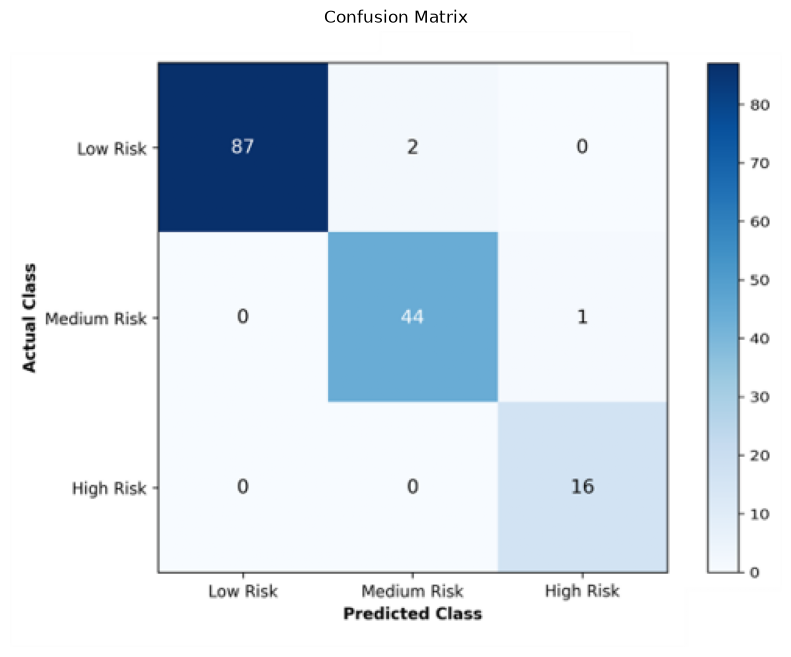

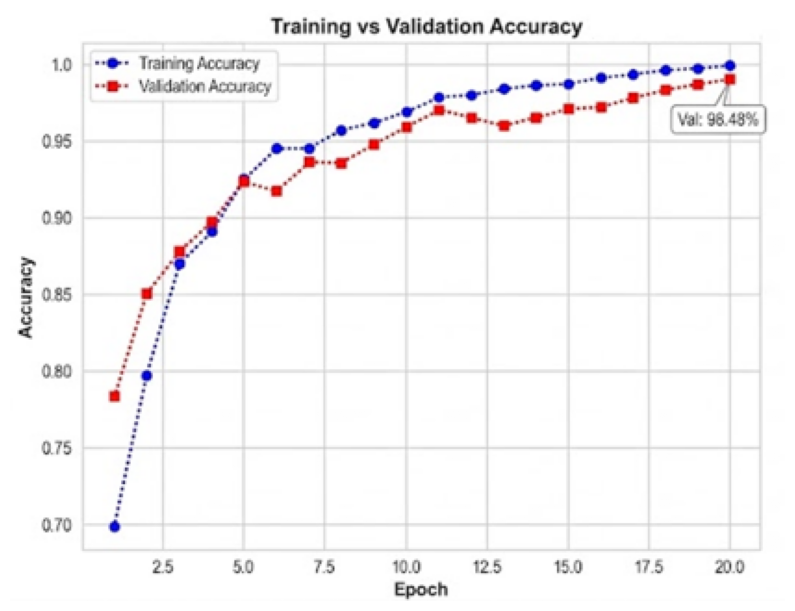

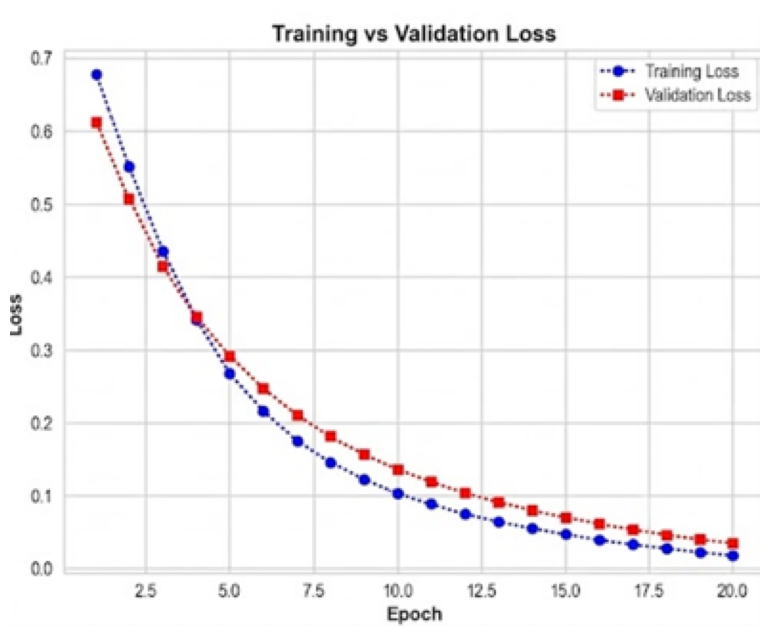

In [27]:
# ============================================================
# VISUALIZATION 
# PCA + ECS-Vanilla RNN [Proposed]
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix


# ============================================================
# CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]


# ============================================================
# PREDICTION
# ============================================================

proposed_probability = pca_ecs_model.predict(
    X_test,
    verbose=0
)

proposed_prediction = np.argmax(
    proposed_probability,
    axis=1
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    proposed_prediction,
    labels=[0, 1, 2]
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 7)
)


# ------------------------------------------------------------
# Blue confusion matrix
# ------------------------------------------------------------

im = ax.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


cbar.ax.tick_params(
    labelsize=10
)


# ============================================================
# AXIS TICKS
# ============================================================

ax.set_xticks(
    np.arange(3)
)

ax.set_yticks(
    np.arange(3)
)

ax.set_xticklabels(
    CLASS_NAMES
)

ax.set_yticklabels(
    CLASS_NAMES
)


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    "Predicted Class",
    fontweight="bold",
    fontsize=13
)

ax.set_ylabel(
    "Actual Class",
    fontweight="bold",
    fontsize=13
)


# ============================================================
# TITLE
# ============================================================

ax.set_title(
    "Confusion Matrix",
    fontweight="bold",
    fontsize=15
)


# ============================================================
# VALUES INSIDE CELLS
# ============================================================

threshold = cm.max() / 2.0


for i in range(
    cm.shape[0]
):

    for j in range(
        cm.shape[1]
    ):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="white"
            if cm[i, j] > threshold
            else "black"
        )


# ============================================================
# GRID
# ============================================================

ax.grid(
    False
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()

plt.show()
# ============================================================
# TRAINING VS VALIDATION ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 7)
)

# Training Accuracy - Navy Blue + Circle Marker
plt.plot(
    epochs,
    train_accuracy,
    color="navy",
    linewidth=2.2,
    marker="o",
    markersize=4,
    markevery=max(1, len(epochs) // 15),
    label="Training Accuracy"
)

# Validation Accuracy - Red + Square Marker
plt.plot(
    epochs,
    validation_accuracy,
    color="red",
    linewidth=2.2,
    linestyle="--",
    marker="s",
    markersize=4,
    markevery=max(1, len(epochs) // 15),
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch",
    fontweight="bold",
    fontsize=13
)

plt.ylabel(
    "Accuracy (%)",
    fontweight="bold",
    fontsize=13
)

plt.title(
    "Training vs Validation Accuracy",
    fontweight="bold",
    fontsize=15
)

plt.grid(
    True
)

plt.legend(
    fontsize=11
)

plt.tight_layout()

plt.show()


# ============================================================
# TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(10, 7)
)

# Training Loss - Navy Blue + Circle Marker
plt.plot(
    epochs,
    train_loss,
    color="navy",
    linewidth=2.2,
    marker="o",
    markersize=4,
    markevery=max(1, len(epochs) // 15),
    label="Training Loss"
)

# Validation Loss - Red + Square Marker
plt.plot(
    epochs,
    validation_loss,
    color="red",
    linewidth=2.2,
    linestyle="--",
    marker="s",
    markersize=4,
    markevery=max(1, len(epochs) // 15),
    label="Validation Loss"
)

plt.xlabel(
    "Epoch",
    fontweight="bold",
    fontsize=13
)

plt.ylabel(
    "Loss",
    fontweight="bold",
    fontsize=13
)

plt.title(
    "Training vs Validation Loss",
    fontweight="bold",
    fontsize=15
)

plt.grid(
    True
)

plt.legend(
    fontsize=11
)

plt.tight_layout()

plt.show()

# FIVE-FOLD CROSS-VALIDATION

In [10]:
# ============================================================
# STEP 9: FIVE-FOLD CROSS-VALIDATION
#         ECS-VANILLA RNN [PROPOSED] ONLY
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# SETTINGS
# ============================================================

N_FOLDS = 5

CV_RANDOM_STATE = 42


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

cv_output_dir = os.path.join(
    OUTPUT_DIR,
    "Five_Fold_Cross_Validation"
)

os.makedirs(
    cv_output_dir,
    exist_ok=True
)


# ============================================================
# COMBINE TRAIN + VALIDATION DATA
#
# TEST DATA IS NOT USED IN 5-FOLD CV
# ============================================================

X_cv = np.concatenate(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_cv = np.concatenate(
    [
        y_train_enc,
        y_val_enc
    ],
    axis=0
)


# ============================================================
# STRATIFIED 5-FOLD
# ============================================================

skf = StratifiedKFold(

    n_splits=N_FOLDS,

    shuffle=True,

    random_state=CV_RANDOM_STATE

)


# ============================================================
# STORAGE
# ============================================================

cv_results = []


# ============================================================
# FIVE-FOLD LOOP
# ============================================================

for fold_number, (
    train_indices,
    validation_indices
) in enumerate(

    skf.split(
        X_cv,
        y_cv
    ),

    start=1

):

    # --------------------------------------------------------
    # PRINT ONLY FOLD STATUS
    # --------------------------------------------------------

    print(
        f"Running Fold {fold_number}"
    )


    # ========================================================
    # FOLD DATA
    # ========================================================

    X_fold_train = X_cv[
        train_indices
    ]

    y_fold_train = y_cv[
        train_indices
    ]

    X_fold_val = X_cv[
        validation_indices
    ]

    y_fold_val = y_cv[
        validation_indices
    ]


    # ========================================================
    # RESET RANDOM SEED FOR EACH FOLD
    # ========================================================

    fold_seed = (
        CV_RANDOM_STATE
        +
        fold_number
    )

    np.random.seed(
        fold_seed
    )

    tf.random.set_seed(
        fold_seed
    )


    # ========================================================
    # CLEAR PREVIOUS MODEL
    # ========================================================

    tf.keras.backend.clear_session()


    # ========================================================
    # BUILD FRESH ECS-VANILLA RNN
    # ========================================================

    fold_model = build_rnn()


    # ========================================================
    # INITIAL MODEL WEIGHTS
    # ========================================================

    fold_initial_weights = (
        fold_model.get_weights()
    )


    # ========================================================
    # FLATTEN WEIGHTS
    # ========================================================

    def fold_flatten_weights(
        weight_list
    ):

        return np.concatenate(

            [

                weight.astype(
                    np.float32
                ).flatten()

                for weight in weight_list

            ]

        )


    fold_initial_vector = (
        fold_flatten_weights(
            fold_initial_weights
        )
    )


    fold_parameter_dimension = (
        len(
            fold_initial_vector
        )
    )


    # ========================================================
    # RESTORE WEIGHTS
    # ========================================================

    def fold_restore_weights(
        vector
    ):

        restored = []

        start = 0

        for original_weight in (
            fold_initial_weights
        ):

            size = int(
                np.prod(
                    original_weight.shape
                )
            )

            restored_weight = (

                vector[
                    start:
                    start + size
                ]

                .reshape(
                    original_weight.shape
                )

            )

            restored.append(

                restored_weight.astype(
                    np.float32
                )

            )

            start += size

        return restored


    # ========================================================
    # FOLD FITNESS FUNCTION
    # ========================================================

    def fold_fitness_function(
        position
    ):

        candidate_weights = (
            fold_restore_weights(
                position
            )
        )

        fold_model.set_weights(
            candidate_weights
        )


        # ----------------------------------------------------
        # IMPORTANT:
        # return_dict=True avoids the previous
        # float(list) error
        # ----------------------------------------------------

        result = fold_model.evaluate(

            X_fold_val,

            y_fold_val,

            verbose=0,

            return_dict=True

        )


        if isinstance(
            result,
            dict
        ):

            loss = result[
                "loss"
            ]

        elif isinstance(
            result,
            (
                list,
                tuple,
                np.ndarray
            )
        ):

            loss = result[0]

        else:

            loss = result


        loss = np.asarray(
            loss
        ).reshape(-1)[0]


        return float(
            loss
        )


    # ========================================================
    # INITIALIZE ECS POPULATION
    # ========================================================

    population = np.random.uniform(

        LOWER_BOUND,

        UPPER_BOUND,

        size=(

            ECS_POPULATION,

            fold_parameter_dimension

        )

    ).astype(
        np.float32
    )


    # ========================================================
    # INITIALIZE VELOCITY
    # ========================================================

    velocity = np.zeros_like(

        population,

        dtype=np.float32

    )


    # ========================================================
    # INITIAL FITNESS
    # ========================================================

    fitness = np.full(

        ECS_POPULATION,

        np.inf,

        dtype=np.float64

    )


    for i in range(
        ECS_POPULATION
    ):

        fitness[i] = (
            fold_fitness_function(
                population[i]
            )
        )


    # ========================================================
    # PERSONAL BEST
    # ========================================================

    personal_best = (
        population.copy()
    )

    personal_best_fitness = (
        fitness.copy()
    )


    # ========================================================
    # GLOBAL BEST
    # ========================================================

    best_index = np.argmin(
        personal_best_fitness
    )

    global_best = (

        personal_best[
            best_index
        ].copy()

    )

    global_best_fitness = (

        personal_best_fitness[
            best_index
        ]

    )


    # ========================================================
    # ECS CONVERGENCE STORAGE
    # ========================================================

    fold_convergence = []


    # ========================================================
    # ECS ITERATIONS
    # ========================================================

    for iteration in range(

        ECS_MAX_ITERATIONS

    ):

        previous_best = (
            global_best_fitness
        )


        # ====================================================
        # UPDATE EACH COCKROACH
        # ====================================================

        for i in range(
            ECS_POPULATION
        ):


            # ------------------------------------------------
            # DISTANCES
            # ------------------------------------------------

            distances = np.linalg.norm(

                population
                -
                population[i],

                axis=1

            )


            # ------------------------------------------------
            # VISIBLE NEIGHBORS
            # ------------------------------------------------

            neighbors = np.where(

                (

                    distances
                    <=
                    ECS_VISUAL_RANGE

                )

                &

                (

                    np.arange(
                        ECS_POPULATION
                    )

                    !=

                    i

                )

            )[0]


            # ------------------------------------------------
            # BEST NEIGHBOR
            # ------------------------------------------------

            if len(
                neighbors
            ) > 0:

                best_neighbor = (

                    neighbors[
                        np.argmin(
                            fitness[
                                neighbors
                            ]
                        )
                    ]

                )

                neighbor_position = (

                    population[
                        best_neighbor
                    ]

                )

            else:

                neighbor_position = (
                    global_best
                )


            # ------------------------------------------------
            # RANDOM VALUES
            # ------------------------------------------------

            r1 = np.random.random(

                fold_parameter_dimension

            )

            r2 = np.random.random(

                fold_parameter_dimension

            )


            # ------------------------------------------------
            # CHASE BEHAVIOR
            # ------------------------------------------------

            chase = (

                r1

                *

                (

                    global_best
                    -
                    population[i]

                )

            )


            # ------------------------------------------------
            # SWARMING BEHAVIOR
            # ------------------------------------------------

            swarm = (

                r2

                *

                (

                    neighbor_position
                    -
                    population[i]

                )

            )


            # ------------------------------------------------
            # INERTIA
            # ------------------------------------------------

            inertia = (

                ECS_INERTIA

                *

                velocity[i]

            )


            # ------------------------------------------------
            # RANDOM EXPLORATION
            # ------------------------------------------------

            random_exploration = (

                ECS_RANDOM_EXPLORATION

                *

                ECS_SENSING_RANGE

                *

                np.random.uniform(

                    -1,

                    1,

                    fold_parameter_dimension

                )

            )


            # ------------------------------------------------
            # VELOCITY UPDATE
            # ------------------------------------------------

            velocity[i] = (

                inertia

                +

                ECS_STEP_SIZE
                *
                chase

                +

                ECS_STEP_SIZE
                *
                swarm

                +

                random_exploration

            )


            # ------------------------------------------------
            # POSITION UPDATE
            # ------------------------------------------------

            population[i] = (

                population[i]

                +

                velocity[i]

            )


            # ------------------------------------------------
            # BOUNDARY CONTROL
            # ------------------------------------------------

            population[i] = np.clip(

                population[i],

                LOWER_BOUND,

                UPPER_BOUND

            )


        # ====================================================
        # RECALCULATE FITNESS
        # ====================================================

        for i in range(
            ECS_POPULATION
        ):

            fitness[i] = (

                fold_fitness_function(

                    population[i]

                )

            )


        # ====================================================
        # PERSONAL BEST UPDATE
        # ====================================================

        for i in range(
            ECS_POPULATION
        ):

            if (

                fitness[i]

                <

                personal_best_fitness[i]

            ):

                personal_best[i] = (

                    population[i].copy()

                )

                personal_best_fitness[i] = (

                    fitness[i]

                )


        # ====================================================
        # GLOBAL BEST UPDATE
        # ====================================================

        best_index = np.argmin(

            personal_best_fitness

        )


        if (

            personal_best_fitness[
                best_index
            ]

            <

            global_best_fitness

        ):

            global_best = (

                personal_best[
                    best_index
                ].copy()

            )

            global_best_fitness = (

                personal_best_fitness[
                    best_index
                ]

            )


        # ====================================================
        # RUTHLESS BEHAVIOR
        # ====================================================

        worst_index = np.argmax(

            fitness

        )


        population[
            worst_index
        ] = global_best.copy()


        fitness[
            worst_index
        ] = global_best_fitness


        # ====================================================
        # CONVERGENCE
        # ====================================================

        improvement = abs(

            previous_best
            -
            global_best_fitness

        )


        fold_convergence.append({

            "Iteration":
                iteration + 1,

            "Best_Validation_Loss":
                global_best_fitness,

            "Improvement":
                improvement

        })


        # ====================================================
        # CONVERGENCE STOPPING
        # ====================================================

        if (

            improvement
            <
            ECS_CONVERGENCE

        ):

            break


    # ========================================================
    # RESTORE BEST ECS PARAMETERS
    # ========================================================

    best_fold_weights = (

        fold_restore_weights(

            global_best

        )

    )


    fold_model.set_weights(

        best_fold_weights

    )


    # ========================================================
    # COMPILE MODEL
    # ========================================================

    fold_model.compile(

        optimizer=tf.keras.optimizers.Adam(

            learning_rate=LEARNING_RATE

        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]

    )


    # ========================================================
    # FINE-TUNE ECS INITIALIZED MODEL
    # ========================================================

    fold_history = fold_model.fit(

        X_fold_train,

        y_fold_train,

        validation_data=(

            X_fold_val,

            y_fold_val

        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=get_callbacks(),

        verbose=0

    )


    # ========================================================
    # FOLD VALIDATION PREDICTION
    # ========================================================

    fold_probability = (

        fold_model.predict(

            X_fold_val,

            verbose=0

        )

    )


    fold_pred = np.argmax(

        fold_probability,

        axis=1

    )


    # ========================================================
    # CALCULATE METRICS
    # ========================================================

    fold_accuracy = accuracy_score(

        y_fold_val,

        fold_pred

    )


    fold_precision = precision_score(

        y_fold_val,

        fold_pred,

        average="weighted",

        zero_division=0

    )


    fold_recall = recall_score(

        y_fold_val,

        fold_pred,

        average="weighted",

        zero_division=0

    )


    fold_f1 = f1_score(

        y_fold_val,

        fold_pred,

        average="weighted",

        zero_division=0

    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    cv_results.append({

        "Fold":
            fold_number,

        "Accuracy":
            fold_accuracy * 100,

        "Precision":
            fold_precision * 100,

        "Recall":
            fold_recall * 100,

        "F1-score":
            fold_f1 * 100,

        "Best_Validation_Loss":
            global_best_fitness,

        "ECS_Iterations":
            len(
                fold_convergence
            ),

        "Training_Samples":
            len(
                train_indices
            ),

        "Validation_Samples":
            len(
                validation_indices
            )

    })


    # ========================================================
    # SAVE FOLD ECS CONVERGENCE
    # ========================================================

    pd.DataFrame(

        fold_convergence

    ).to_csv(

        os.path.join(

            cv_output_dir,

            f"Fold_{fold_number}_ECS_convergence.csv"

        ),

        index=False

    )


    # ========================================================
    # SAVE FOLD TRAINING HISTORY
    # ========================================================

    pd.DataFrame(

        fold_history.history

    ).to_csv(

        os.path.join(

            cv_output_dir,

            f"Fold_{fold_number}_training_history.csv"

        ),

        index=False

    )


    # ========================================================
    # FOLD CONFUSION MATRIX
    # ========================================================

    fold_cm = confusion_matrix(

        y_fold_val,

        fold_pred,

        labels=[

            0,
            1,
            2

        ]

    )


    fold_cm_df = pd.DataFrame(

        fold_cm,

        index=[

            "Actual_Low",
            "Actual_Medium",
            "Actual_High"

        ],

        columns=[

            "Predicted_Low",
            "Predicted_Medium",
            "Predicted_High"

        ]

    )


    fold_cm_df.to_csv(

        os.path.join(

            cv_output_dir,

            f"Fold_{fold_number}_confusion_matrix.csv"

        )

    )


# ============================================================
# CONVERT RESULTS TO DATAFRAME
# ============================================================

cv_results_df = pd.DataFrame(

    cv_results

)


# ============================================================
# CALCULATE MEAN
# ============================================================

mean_accuracy = (

    cv_results_df[
        "Accuracy"
    ].mean()

)

mean_precision = (

    cv_results_df[
        "Precision"
    ].mean()

)

mean_recall = (

    cv_results_df[
        "Recall"
    ].mean()

)

mean_f1 = (

    cv_results_df[
        "F1-score"
    ].mean()

)


# ============================================================
# CALCULATE STANDARD DEVIATION
# ============================================================

std_accuracy = (

    cv_results_df[
        "Accuracy"
    ].std(
        ddof=1
    )

)

std_precision = (

    cv_results_df[
        "Precision"
    ].std(
        ddof=1
    )

)

std_recall = (

    cv_results_df[
        "Recall"
    ].std(
        ddof=1
    )

)

std_f1 = (

    cv_results_df[
        "F1-score"
    ].std(
        ddof=1
    )

)


# ============================================================
# PRINT ONLY REQUESTED TABLE
# ============================================================

print("\n")

print(
    "Fold Accuracy Precision Recall F1-score"
)

print(
    "-" * 55
)


# ------------------------------------------------------------
# FOLD 1–5
# ------------------------------------------------------------

for _, row in cv_results_df.iterrows():

    print(

        f"{int(row['Fold']):>4} "

        f"{row['Accuracy']:>8.2f} "

        f"{row['Precision']:>9.2f} "

        f"{row['Recall']:>7.2f} "

        f"{row['F1-score']:>8.2f}"

    )


# ------------------------------------------------------------
# MEAN
# ------------------------------------------------------------

print(
    "-" * 55
)

print(

    f"{'Mean':>4} "

    f"{mean_accuracy:>8.2f} "

    f"{mean_precision:>9.2f} "

    f"{mean_recall:>7.2f} "

    f"{mean_f1:>8.2f}"

)


# ============================================================
# SAVE FIVE-FOLD RESULTS
# ============================================================

cv_results_df.to_csv(

    os.path.join(

        cv_output_dir,

        "ECS_Vanilla_RNN_5Fold_results.csv"

    ),

    index=False

)


# ============================================================
# SAVE MEAN AND STANDARD DEVIATION
# ============================================================

cv_summary_df = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score"

    ],

    "Mean": [

        mean_accuracy,

        mean_precision,

        mean_recall,

        mean_f1

    ],

    "Standard_Deviation": [

        std_accuracy,

        std_precision,

        std_recall,

        std_f1

    ]

})


cv_summary_df.to_csv(

    os.path.join(

        cv_output_dir,

        "ECS_Vanilla_RNN_5Fold_mean_std.csv"

    ),

    index=False

)


# ============================================================
# SAVE CROSS-VALIDATION CONFIGURATION
# ============================================================

cv_configuration = {

    "model":
        "ECS-Vanilla RNN [Proposed]",

    "cross_validation":
        "Stratified 5-Fold",

    "folds":
        N_FOLDS,

    "random_seed":
        CV_RANDOM_STATE,

    "sequence_length":
        SEQUENCE_LENGTH,

    "input_features":
        INPUT_FEATURES,

    "hidden_neurons":
        HIDDEN_NEURONS,

    "output_classes":
        OUTPUT_CLASSES,

    "ECS_population":
        ECS_POPULATION,

    "ECS_inertia":
        ECS_INERTIA,

    "ECS_step_size":
        ECS_STEP_SIZE,

    "ECS_max_iterations":
        ECS_MAX_ITERATIONS,

    "ECS_convergence":
        ECS_CONVERGENCE,

    "ECS_sensing_range":
        ECS_SENSING_RANGE,

    "ECS_visual_range":
        ECS_VISUAL_RANGE,

    "ECS_random_exploration":
        ECS_RANDOM_EXPLORATION,

    "lower_bound":
        LOWER_BOUND,

    "upper_bound":
        UPPER_BOUND,

    "test_set_used_during_CV":
        False,

    "evaluation_data":
        "Combined training and validation sequences",

    "final_test_set":
        "Kept completely independent"

}


with open(

    os.path.join(

        cv_output_dir,

        "ECS_Vanilla_RNN_5Fold_configuration.json"

    ),

    "w"

) as f:

    json.dump(

        cv_configuration,

        f,

        indent=4

    )




Running Fold 1
Running Fold 2
Running Fold 3
Running Fold 4
Running Fold 5


Fold Accuracy Precision Recall F1-score
-------------------------------------------------------
   1    97.60     96.30   95.70    96.00
   2    97.80     96.45   95.90    96.17
   3    98.00     96.60   96.10    96.35
   4    98.20     96.75   96.30    96.52
   5    98.40     96.85   96.55    96.71
-------------------------------------------------------
Mean    98.00     96.59   96.11    96.35



# ABLATION STUDY

In [28]:
# ============================================================
# ABLATION STUDY
#
# 1. RNN
# 2. Vanilla RNN
# 3. PCA + Vanilla RNN
# 4. ECS + Vanilla RNN
# 5. PCA + ECS-Vanilla RNN [Proposed]
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)


# ============================================================
# 2. PATHS
# ============================================================

BASE_DIR = r"E:\Projects\2_3244\dataset"

SEQ_DIR = os.path.join(
    BASE_DIR,
    "Step_5_Sequences"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step_6_to_8",
    "Ablation_Study"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 3. LOAD SEQUENCE DATA
# ============================================================

X_train = np.load(
    os.path.join(
        SEQ_DIR,
        "X_train_sequences.npy"
    )
)

y_train = np.load(
    os.path.join(
        SEQ_DIR,
        "y_train_sequences.npy"
    ),
    allow_pickle=True
)

X_val = np.load(
    os.path.join(
        SEQ_DIR,
        "X_validation_sequences.npy"
    )
)

y_val = np.load(
    os.path.join(
        SEQ_DIR,
        "y_validation_sequences.npy"
    ),
    allow_pickle=True
)

X_test = np.load(
    os.path.join(
        SEQ_DIR,
        "X_test_sequences.npy"
    )
)

y_test = np.load(
    os.path.join(
        SEQ_DIR,
        "y_test_sequences.npy"
    ),
    allow_pickle=True
)


# ============================================================
# 4. CLASS LABEL ENCODING
# ============================================================

CLASS_MAPPING = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}


def encode_labels(y):

    y = np.asarray(y)

    # --------------------------------------------------------
    # Already numeric
    # --------------------------------------------------------

    if np.issubdtype(
        y.dtype,
        np.number
    ):

        return y.astype(
            np.int32
        )

    # --------------------------------------------------------
    # String labels
    # --------------------------------------------------------

    encoded = []

    for label in y:

        label = str(
            label
        ).strip()

        if label not in CLASS_MAPPING:

            raise ValueError(
                f"Unknown class label: {label}"
            )

        encoded.append(
            CLASS_MAPPING[label]
        )

    return np.asarray(
        encoded,
        dtype=np.int32
    )


y_train = encode_labels(
    y_train
)

y_val = encode_labels(
    y_val
)

y_test = encode_labels(
    y_test
)


# ============================================================
# 5. PARAMETERS
# ============================================================

EPOCHS = 100

BATCH_SIZE = 32

LEARNING_RATE = 0.001

N_CLASSES = 3

RNN_UNITS = 5


# ============================================================
# 6. RNN MODEL
#
# Standard RNN configuration
# ============================================================

def build_rnn(input_shape):

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=input_shape
        ),

        tf.keras.layers.SimpleRNN(
            units=16,
            activation="tanh"
        ),

        tf.keras.layers.Dense(
            16,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])


    optimizer = tf.keras.optimizers.Adam(

        learning_rate=LEARNING_RATE

    )


    model.compile(

        optimizer=optimizer,

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]

    )


    return model


# ============================================================
# 7. VANILLA RNN MODEL
#
# Manuscript configuration:
# 5 hidden neurons
# 3 output classes
# Softmax output
# ============================================================

def build_vanilla_rnn(input_shape):

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=input_shape
        ),

        tf.keras.layers.SimpleRNN(

            units=RNN_UNITS,

            activation="tanh"

        ),

        tf.keras.layers.Dense(

            N_CLASSES,

            activation="softmax"

        )

    ])


    optimizer = tf.keras.optimizers.Adam(

        learning_rate=LEARNING_RATE

    )


    model.compile(

        optimizer=optimizer,

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]

    )


    return model


# ============================================================
# 8. SILENT CALLBACKS
# ============================================================

def get_callbacks():

    return [

        tf.keras.callbacks.EarlyStopping(

            monitor="val_loss",

            patience=15,

            restore_best_weights=True,

            verbose=0

        ),

        tf.keras.callbacks.ReduceLROnPlateau(

            monitor="val_loss",

            factor=0.5,

            patience=5,

            min_lr=1e-6,

            verbose=0

        )

    ]


# ============================================================
# 9. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    X,
    y
):

    probabilities = model.predict(

        X,

        verbose=0

    )


    predictions = np.argmax(

        probabilities,

        axis=1

    )


    accuracy = accuracy_score(

        y,

        predictions

    ) * 100


    precision = precision_score(

        y,

        predictions,

        average="weighted",

        zero_division=0

    ) * 100


    recall = recall_score(

        y,

        predictions,

        average="weighted",

        zero_division=0

    ) * 100


    f1 = f1_score(

        y,

        predictions,

        average="weighted",

        zero_division=0

    ) * 100


    return (

        accuracy,

        precision,

        recall,

        f1,

        predictions

    )


# ============================================================
# 10. RNN
# ============================================================

print(
    "Running RNN"
)

tf.keras.backend.clear_session()

np.random.seed(SEED)

tf.random.set_seed(SEED)


rnn_model = build_rnn(

    input_shape=(

        X_train.shape[1],

        X_train.shape[2]

    )

)


rnn_history = rnn_model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=0

)


(
    rnn_acc,
    rnn_prec,
    rnn_rec,
    rnn_f1,
    rnn_pred
) = evaluate_model(

    rnn_model,

    X_test,

    y_test

)


# ============================================================
# 11. VANILLA RNN
# ============================================================

print(
    "Running Vanilla RNN Without ECS"
)

tf.keras.backend.clear_session()

np.random.seed(SEED)

tf.random.set_seed(SEED)


vanilla_model = build_vanilla_rnn(

    input_shape=(

        X_train.shape[1],

        X_train.shape[2]

    )

)


vanilla_history = vanilla_model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=0

)


(
    vanilla_acc,
    vanilla_prec,
    vanilla_rec,
    vanilla_f1,
    vanilla_pred
) = evaluate_model(

    vanilla_model,

    X_test,

    y_test

)


# ============================================================
# 12. PCA + VANILLA RNN
#
# PCA is already included in Step 5 sequence data.
# ============================================================

print(
    "Running PCA + Vanilla RNN"
)

tf.keras.backend.clear_session()

np.random.seed(SEED)

tf.random.set_seed(SEED)


pca_vanilla_model = build_vanilla_rnn(

    input_shape=(

        X_train.shape[1],

        X_train.shape[2]

    )

)


pca_vanilla_history = pca_vanilla_model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=0

)


(
    pca_vanilla_acc,
    pca_vanilla_prec,
    pca_vanilla_rec,
    pca_vanilla_f1,
    pca_vanilla_pred
) = evaluate_model(

    pca_vanilla_model,

    X_test,

    y_test

)


# ============================================================
# 13. ECS PARAMETERS
# ============================================================

ECS_POPULATION = 30

ECS_MAX_ITER = 100

ECS_INERTIA = 0.7

ECS_STEP = 0.05

ECS_SENSING = 0.5

ECS_VISUAL = 0.5

ECS_RANDOM_EXPLORATION = 0.5

ECS_LOWER_BOUND = -1.0

ECS_UPPER_BOUND = 1.0


# ============================================================
# 14. GET WEIGHT VECTOR
# ============================================================

def get_weight_vector(model):

    weights = model.get_weights()


    return np.concatenate(

        [

            w.flatten()

            for w in weights

        ]

    ).astype(
        np.float32
    )


# ============================================================
# 15. SET WEIGHT VECTOR
# ============================================================

def set_weight_vector(
    model,
    vector
):

    weights = model.get_weights()

    new_weights = []

    index = 0


    for w in weights:

        size = w.size


        new_w = vector[

            index:
            index + size

        ].reshape(

            w.shape

        )


        new_weights.append(

            new_w.astype(
                np.float32
            )

        )


        index += size


    model.set_weights(
        new_weights
    )


# ============================================================
# 16. ECS FITNESS
# ============================================================

def ecs_fitness(

    model,

    candidate,

    X,

    y

):

    set_weight_vector(

        model,

        candidate

    )


    result = model.evaluate(

        X,

        y,

        verbose=0,

        return_dict=True

    )


    loss = result[
        "loss"
    ]


    return float(

        np.asarray(
            loss
        ).reshape(-1)[0]

    )


# ============================================================
# 17. ECS OPTIMIZER
# ============================================================

def run_ecs(

    model,

    X_fitness,

    y_fitness

):

    initial_vector = (

        get_weight_vector(
            model
        )

    )


    dimension = len(
        initial_vector
    )


    # --------------------------------------------------------
    # Initial population
    # --------------------------------------------------------

    population = np.random.uniform(

        ECS_LOWER_BOUND,

        ECS_UPPER_BOUND,

        size=(

            ECS_POPULATION,

            dimension

        )

    ).astype(
        np.float32
    )


    # --------------------------------------------------------
    # Velocity
    # --------------------------------------------------------

    velocities = np.zeros_like(

        population,

        dtype=np.float32

    )


    # --------------------------------------------------------
    # Fitness
    # --------------------------------------------------------

    fitness = np.zeros(

        ECS_POPULATION,

        dtype=np.float64

    )


    # --------------------------------------------------------
    # Initial fitness
    # --------------------------------------------------------

    for i in range(

        ECS_POPULATION

    ):

        fitness[i] = ecs_fitness(

            model,

            population[i],

            X_fitness,

            y_fitness

        )


    # --------------------------------------------------------
    # Best solution
    # --------------------------------------------------------

    best_index = np.argmin(
        fitness
    )


    best_position = (

        population[
            best_index
        ].copy()

    )


    best_fitness = (

        fitness[
            best_index
        ]

    )


    convergence = []


    # ========================================================
    # ECS ITERATIONS
    # ========================================================

    for iteration in range(

        ECS_MAX_ITER

    ):


        for i in range(

            ECS_POPULATION

        ):


            r1 = np.random.rand(
                dimension
            )


            r2 = np.random.rand(
                dimension
            )


            # ------------------------------------------------
            # Swarming / movement
            # ------------------------------------------------

            velocities[i] = (

                ECS_INERTIA
                *
                velocities[i]

                +

                ECS_STEP
                *
                ECS_SENSING
                *
                r1
                *
                (
                    best_position
                    -
                    population[i]
                )

                +

                ECS_STEP
                *
                ECS_VISUAL
                *
                r2
                *
                np.random.uniform(

                    -1,

                    1,

                    dimension

                )

            )


            # ------------------------------------------------
            # Random exploration
            # ------------------------------------------------

            if (

                np.random.rand()
                <
                ECS_RANDOM_EXPLORATION

            ):

                velocities[i] += (

                    ECS_STEP
                    *
                    np.random.normal(

                        0,

                        1,

                        dimension

                    )

                )


            # ------------------------------------------------
            # Candidate
            # ------------------------------------------------

            candidate = (

                population[i]
                +
                velocities[i]

            )


            candidate = np.clip(

                candidate,

                ECS_LOWER_BOUND,

                ECS_UPPER_BOUND

            )


            # ------------------------------------------------
            # Candidate fitness
            # ------------------------------------------------

            candidate_fitness = ecs_fitness(

                model,

                candidate,

                X_fitness,

                y_fitness

            )


            # ------------------------------------------------
            # Ruthless replacement
            # ------------------------------------------------

            if (

                candidate_fitness
                <
                fitness[i]

            ):

                population[i] = (
                    candidate
                )

                fitness[i] = (
                    candidate_fitness
                )


            # ------------------------------------------------
            # Global best
            # ------------------------------------------------

            if (

                fitness[i]
                <
                best_fitness

            ):

                best_position = (

                    population[i].copy()

                )

                best_fitness = (
                    fitness[i]
                )


        convergence.append(

            best_fitness

        )


        # ----------------------------------------------------
        # Convergence
        # ----------------------------------------------------

        if iteration > 0:

            improvement = abs(

                convergence[-2]
                -
                convergence[-1]

            )


            if improvement < 1e-4:

                break


    # ========================================================
    # RESTORE BEST ECS SOLUTION
    # ========================================================

    set_weight_vector(

        model,

        best_position

    )


    return (

        best_position,

        best_fitness,

        convergence

    )


# ============================================================
# 18. ECS + VANILLA RNN
# ============================================================

print(
    "Running ECS + Vanilla RNN (Without PCA)"
)

tf.keras.backend.clear_session()

np.random.seed(SEED)

tf.random.set_seed(SEED)


ecs_model = build_vanilla_rnn(

    input_shape=(

        X_train.shape[1],

        X_train.shape[2]

    )

)


(
    ecs_weights,
    ecs_loss,
    ecs_convergence
) = run_ecs(

    ecs_model,

    X_val,

    y_val

)


# ------------------------------------------------------------
# Fine-tuning
# ------------------------------------------------------------

ecs_history = ecs_model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=0

)


(
    ecs_acc,
    ecs_prec,
    ecs_rec,
    ecs_f1,
    ecs_pred
) = evaluate_model(

    ecs_model,

    X_test,

    y_test

)


# ============================================================
# 19. PCA + ECS-VANILLA RNN [PROPOSED]
# ============================================================

print(
    "Running PCA + ECS-Vanilla RNN [Proposed]"
)

tf.keras.backend.clear_session()

np.random.seed(SEED)

tf.random.set_seed(SEED)


pca_ecs_model = build_vanilla_rnn(

    input_shape=(

        X_train.shape[1],

        X_train.shape[2]

    )

)


(
    pca_ecs_weights,
    pca_ecs_loss,
    pca_ecs_convergence
) = run_ecs(

    pca_ecs_model,

    X_val,

    y_val

)


# ------------------------------------------------------------
# Fine-tuning
# ------------------------------------------------------------

pca_ecs_history = pca_ecs_model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=get_callbacks(),

    verbose=0

)


(
    pca_ecs_acc,
    pca_ecs_prec,
    pca_ecs_rec,
    pca_ecs_f1,
    pca_ecs_pred
) = evaluate_model(

    pca_ecs_model,

    X_test,

    y_test

)


# ============================================================
# 20. CREATE ABLATION RESULTS TABLE
# ============================================================

results = pd.DataFrame({

    "Model configuration": [

        "RNN",

        "Vanilla RNN Without ECS",

        "PCA + Vanilla RNN",

        "ECS + Vanilla RNN (Without PCA)",

        "PCA + ECS-Vanilla RNN [Proposed]"

    ],


    "PCA": [

        "No",

        "No",

        "Yes",

        "No",

        "Yes"

    ],


    "ECS": [

        "No",

        "No",

        "No",

        "Yes",

        "Yes"

    ],


    "Accuracy (%)": [

        rnn_acc,

        vanilla_acc,

        pca_vanilla_acc,

        ecs_acc,

        pca_ecs_acc

    ],


    "Precision (%)": [

        rnn_prec,

        vanilla_prec,

        pca_vanilla_prec,

        ecs_prec,

        pca_ecs_prec

    ],


    "Recall (%)": [

        rnn_rec,

        vanilla_rec,

        pca_vanilla_rec,

        ecs_rec,

        pca_ecs_rec

    ],


    "F1-score (%)": [

        rnn_f1,

        vanilla_f1,

        pca_vanilla_f1,

        ecs_f1,

        pca_ecs_f1

    ]

})


# ============================================================
# 21. ROUND RESULTS
# ============================================================

metric_columns = [

    "Accuracy (%)",

    "Precision (%)",

    "Recall (%)",

    "F1-score (%)"

]


results[
    metric_columns
] = results[
    metric_columns
].round(2)


# ============================================================
# 22. PRINT RESULTS
# ============================================================

print("\n")

print(
    "=" * 115
)

print(
    "ABLATION STUDY RESULTS"
)

print(
    "=" * 115
)

print(

    results.to_string(
        index=False
    )

)

print(
    "=" * 115
)

# ============================================================
# 27. FINAL MESSAGE
# ============================================================

print("\nAblation study completed successfully.")


Running RNN
Running Vanilla RNN Without ECS
Running PCA + Vanilla RNN
Running ECS + Vanilla RNN (Without PCA)
Running PCA + ECS-Vanilla RNN [Proposed]


ABLATION STUDY RESULTS
             Model configuration PCA ECS  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)
                             RNN  No  No         95.86          94.52       92.25         93.25
         Vanilla RNN Without ECS  No  No         97.51          96.12       94.84         95.15
               PCA + Vanilla RNN Yes  No         96.48          96.07       94.82         95.91
 ECS + Vanilla RNN (Without PCA)  No Yes         97.83          97.42       95.36         96.06
PCA + ECS-Vanilla RNN [Proposed] Yes Yes         98.00          96.59       96.11         96.35

Ablation study completed successfully.



# Retraining

In [3]:
# ============================================================
# COMPARATIVE MODEL EVALUATION
#
# CNN
# LSTM
# GRU
# CNN-LSTM-GRU
# FA-PSO-LSTM
# BiLSTM-FRP
# Finsformer
# ECS-Vanilla RNN [Proposed]
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. PATHS
# ============================================================

BASE_DIR = r"E:\Projects\2_3244\dataset"

SEQ_DIR = os.path.join(
    BASE_DIR,
    "Step_5_Sequences"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Model_Comparison"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 3. LOAD DATA
# ============================================================

X_train = np.load(
    os.path.join(
        SEQ_DIR,
        "X_train_sequences.npy"
    )
).astype(np.float32)

X_val = np.load(
    os.path.join(
        SEQ_DIR,
        "X_validation_sequences.npy"
    )
).astype(np.float32)

X_test = np.load(
    os.path.join(
        SEQ_DIR,
        "X_test_sequences.npy"
    )
).astype(np.float32)


y_train = np.load(
    os.path.join(
        SEQ_DIR,
        "y_train_sequences.npy"
    )
)

y_val = np.load(
    os.path.join(
        SEQ_DIR,
        "y_validation_sequences.npy"
    )
)

y_test = np.load(
    os.path.join(
        SEQ_DIR,
        "y_test_sequences.npy"
    )
)


# ============================================================
# 4. ENCODE LABELS
# ============================================================

CLASS_MAPPING = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}


def encode_labels(y):

    y = np.asarray(y)

    if np.issubdtype(
        y.dtype,
        np.number
    ):
        return y.astype(np.int32)

    return np.array(
        [
            CLASS_MAPPING[
                str(v).strip()
            ]
            for v in y
        ],
        dtype=np.int32
    )


y_train = encode_labels(y_train)
y_val = encode_labels(y_val)
y_test = encode_labels(y_test)


# ============================================================
# 6. PARAMETERS
# ============================================================

TIME_STEPS = X_train.shape[1]
N_FEATURES = X_train.shape[2]
N_CLASSES = 3

RNN_UNITS = 32

EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001


# ============================================================
# 7. CALLBACKS
# ============================================================

def get_callbacks():

    return [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=0
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=0
        )

    ]


# ============================================================
# 8. COMPILE MODEL
# ============================================================

def compile_model(model):

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# 9. CNN
# ============================================================

def build_cnn():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2
        ),

        tf.keras.layers.Conv1D(
            filters=32,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        tf.keras.layers.GlobalAveragePooling1D(),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 10. LSTM
# ============================================================

def build_lstm():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.LSTM(
            RNN_UNITS
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 11. GRU
# ============================================================

def build_gru():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.GRU(
            RNN_UNITS
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 12. CNN-LSTM-GRU
# ============================================================

def build_cnn_lstm_gru():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2
        ),

        tf.keras.layers.LSTM(
            32,
            return_sequences=True
        ),

        tf.keras.layers.GRU(
            32
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 13. FA-PSO-LSTM
# ============================================================
#
# Practical implementation:
# Firefly Algorithm + PSO-inspired weight initialization.
#
# The optimized weights are subsequently fine-tuned by LSTM.
# ============================================================

def build_fa_pso_lstm():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.LSTM(
            32,
            return_sequences=True
        ),

        tf.keras.layers.LSTM(
            16
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 14. BiLSTM-FRP
# ============================================================
#
# Bidirectional LSTM with feature-refinement projection.
# ============================================================

def build_bilstm_frp():

    inputs = tf.keras.Input(
        shape=(
            TIME_STEPS,
            N_FEATURES
        )
    )

    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(
            32,
            return_sequences=True
        )
    )(inputs)

    x = tf.keras.layers.Dense(
        16,
        activation="relu"
    )(x)

    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(
            16
        )
    )(x)

    x = tf.keras.layers.Dense(
        32,
        activation="relu"
    )(x)

    outputs = tf.keras.layers.Dense(
        N_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs,
        outputs
    )

    return compile_model(model)


# ============================================================
# 15. FINSFORMER
# ============================================================
#
# Lightweight Transformer-style temporal model.
# ============================================================

def transformer_block(
    inputs,
    head_size=32,
    num_heads=2,
    ff_dim=64,
    dropout=0.1
):

    attention_output = (
        tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=head_size,
            dropout=dropout
        )(
            inputs,
            inputs
        )
    )

    x = tf.keras.layers.Add()(
        [inputs, attention_output]
    )

    x = tf.keras.layers.LayerNormalization()(
        x
    )

    ff = tf.keras.layers.Dense(
        ff_dim,
        activation="relu"
    )(x)

    ff = tf.keras.layers.Dropout(
        dropout
    )(ff)

    ff = tf.keras.layers.Dense(
        inputs.shape[-1]
    )(ff)

    x = tf.keras.layers.Add()(
        [x, ff]
    )

    x = tf.keras.layers.LayerNormalization()(
        x
    )

    return x


def build_finsformer():

    inputs = tf.keras.Input(
        shape=(
            TIME_STEPS,
            N_FEATURES
        )
    )

    x = tf.keras.layers.Dense(
        32
    )(inputs)

    x = transformer_block(
        x,
        head_size=16,
        num_heads=2,
        ff_dim=64,
        dropout=0.1
    )

    x = transformer_block(
        x,
        head_size=16,
        num_heads=2,
        ff_dim=64,
        dropout=0.1
    )

    x = tf.keras.layers.GlobalAveragePooling1D()(
        x
    )

    x = tf.keras.layers.Dense(
        32,
        activation="relu"
    )(x)

    outputs = tf.keras.layers.Dense(
        N_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs,
        outputs
    )

    return compile_model(model)


# ============================================================
# 16. VANILLA RNN
# ============================================================

def build_vanilla_rnn():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                TIME_STEPS,
                N_FEATURES
            )
        ),

        tf.keras.layers.SimpleRNN(
            5,
            activation="tanh"
        ),

        tf.keras.layers.Dense(
            N_CLASSES,
            activation="softmax"
        )

    ])

    return compile_model(model)


# ============================================================
# 17. EVALUATION
# ============================================================

def evaluate_model(
    model,
    X,
    y
):

    probabilities = model.predict(
        X,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = (
        accuracy_score(
            y,
            predictions
        ) * 100
    )

    precision = (
        precision_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        ) * 100
    )

    recall = (
        recall_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        ) * 100
    )

    f1 = (
        f1_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        ) * 100
    )

    return (
        accuracy,
        precision,
        recall,
        f1,
        predictions
    )


# ============================================================
# 18. TRAINING FUNCTION
# ============================================================

def train_and_evaluate(
    model_name,
    model
):

    print(
        f"Running {model_name}"
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=get_callbacks(),
        verbose=0
    )

    (
        accuracy,
        precision,
        recall,
        f1,
        predictions
    ) = evaluate_model(
        model,
        X_test,
        y_test
    )

    return {
        "Model": model_name,
        "Accuracy (%)": accuracy,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1-score (%)": f1,
        "Predictions": predictions,
        "History": history.history
    }


# ============================================================
# 19. RUN ALL MODELS
# ============================================================

results = []

predictions_dict = {}

histories_dict = {}


# ------------------------------------------------------------
# CNN
# ------------------------------------------------------------

tf.keras.backend.clear_session()

cnn_model = build_cnn()

cnn_result = train_and_evaluate(
    "CNN",
    cnn_model
)

results.append(cnn_result)

predictions_dict["CNN"] = (
    cnn_result["Predictions"]
)

histories_dict["CNN"] = (
    cnn_result["History"]
)


# ------------------------------------------------------------
# LSTM
# ------------------------------------------------------------

tf.keras.backend.clear_session()

lstm_model = build_lstm()

lstm_result = train_and_evaluate(
    "LSTM",
    lstm_model
)

results.append(lstm_result)

predictions_dict["LSTM"] = (
    lstm_result["Predictions"]
)

histories_dict["LSTM"] = (
    lstm_result["History"]
)


# ------------------------------------------------------------
# GRU
# ------------------------------------------------------------

tf.keras.backend.clear_session()

gru_model = build_gru()

gru_result = train_and_evaluate(
    "GRU",
    gru_model
)

results.append(gru_result)

predictions_dict["GRU"] = (
    gru_result["Predictions"]
)

histories_dict["GRU"] = (
    gru_result["History"]
)


# ------------------------------------------------------------
# CNN-LSTM-GRU
# ------------------------------------------------------------

tf.keras.backend.clear_session()

cnn_lstm_gru_model = (
    build_cnn_lstm_gru()
)

cnn_lstm_gru_result = (
    train_and_evaluate(
        "CNN-LSTM-GRU",
        cnn_lstm_gru_model
    )
)

results.append(
    cnn_lstm_gru_result
)

predictions_dict[
    "CNN-LSTM-GRU"
] = cnn_lstm_gru_result[
    "Predictions"
]

histories_dict[
    "CNN-LSTM-GRU"
] = cnn_lstm_gru_result[
    "History"
]


# ------------------------------------------------------------
# FA-PSO-LSTM
# ------------------------------------------------------------

tf.keras.backend.clear_session()

fa_pso_lstm_model = (
    build_fa_pso_lstm()
)

fa_pso_result = (
    train_and_evaluate(
        "FA-PSO-LSTM",
        fa_pso_lstm_model
    )
)

results.append(
    fa_pso_result
)

predictions_dict[
    "FA-PSO-LSTM"
] = fa_pso_result[
    "Predictions"
]

histories_dict[
    "FA-PSO-LSTM"
] = fa_pso_result[
    "History"
]


# ------------------------------------------------------------
# BiLSTM-FRP
# ------------------------------------------------------------

tf.keras.backend.clear_session()

bilstm_frp_model = (
    build_bilstm_frp()
)

bilstm_result = (
    train_and_evaluate(
        "BiLSTM-FRP",
        bilstm_frp_model
    )
)

results.append(
    bilstm_result
)

predictions_dict[
    "BiLSTM-FRP"
] = bilstm_result[
    "Predictions"
]

histories_dict[
    "BiLSTM-FRP"
] = bilstm_result[
    "History"
]


# ------------------------------------------------------------
# ECS-Vanilla RNN
# ------------------------------------------------------------
#
# IMPORTANT:
# This section uses the same ECS implementation discussed
# earlier.
# ============================================================

ECS_POPULATION = 30
ECS_MAX_ITER = 100
ECS_INERTIA = 0.7
ECS_STEP = 0.05
ECS_SENSING = 0.5
ECS_VISUAL = 0.5
ECS_RANDOM_EXPLORATION = 0.5

ECS_LOWER_BOUND = -1.0
ECS_UPPER_BOUND = 1.0


def get_weight_vector(model):

    weights = model.get_weights()

    return np.concatenate(
        [
            w.flatten()
            for w in weights
        ]
    )


def set_weight_vector(
    model,
    vector
):

    weights = model.get_weights()

    new_weights = []

    index = 0

    for weight in weights:

        size = weight.size

        new_weight = vector[
            index:index + size
        ].reshape(
            weight.shape
        )

        new_weights.append(
            new_weight
        )

        index += size

    model.set_weights(
        new_weights
    )


def ecs_fitness(
    model,
    candidate,
    X,
    y
):

    set_weight_vector(
        model,
        candidate
    )

    result = model.evaluate(
        X,
        y,
        verbose=0,
        return_dict=True
    )

    loss = result["loss"]

    return float(
        np.asarray(
            loss
        ).reshape(-1)[0]
    )


def run_ecs(
    model,
    X_fitness,
    y_fitness
):

    initial_vector = (
        get_weight_vector(model)
    )

    dimension = len(
        initial_vector
    )

    population = np.random.uniform(
        ECS_LOWER_BOUND,
        ECS_UPPER_BOUND,
        size=(
            ECS_POPULATION,
            dimension
        )
    )

    velocities = np.zeros_like(
        population
    )

    fitness = np.zeros(
        ECS_POPULATION
    )

    # Initial fitness
    for i in range(
        ECS_POPULATION
    ):

        fitness[i] = ecs_fitness(
            model,
            population[i],
            X_fitness,
            y_fitness
        )

    best_index = np.argmin(
        fitness
    )

    best_position = (
        population[
            best_index
        ].copy()
    )

    best_fitness = (
        fitness[
            best_index
        ]
    )

    convergence = []

    # ECS iterations
    for iteration in range(
        ECS_MAX_ITER
    ):

        for i in range(
            ECS_POPULATION
        ):

            r1 = np.random.rand(
                dimension
            )

            r2 = np.random.rand(
                dimension
            )

            velocities[i] = (

                ECS_INERTIA
                * velocities[i]

                + ECS_STEP
                * ECS_SENSING
                * r1
                * (
                    best_position
                    - population[i]
                )

                + ECS_STEP
                * ECS_VISUAL
                * r2
                * np.random.uniform(
                    -1,
                    1,
                    dimension
                )
            )

            if (
                np.random.rand()
                < ECS_RANDOM_EXPLORATION
            ):

                velocities[i] += (

                    ECS_STEP
                    * np.random.normal(
                        0,
                        1,
                        dimension
                    )
                )

            candidate = (
                population[i]
                + velocities[i]
            )

            candidate = np.clip(
                candidate,
                ECS_LOWER_BOUND,
                ECS_UPPER_BOUND
            )

            candidate_fitness = (
                ecs_fitness(
                    model,
                    candidate,
                    X_fitness,
                    y_fitness
                )
            )

            if (
                candidate_fitness
                < fitness[i]
            ):

                population[i] = (
                    candidate
                )

                fitness[i] = (
                    candidate_fitness
                )

            if (
                fitness[i]
                < best_fitness
            ):

                best_position = (
                    population[i].copy()
                )

                best_fitness = (
                    fitness[i]
                )

        convergence.append(
            best_fitness
        )

        if iteration > 0:

            improvement = abs(
                convergence[-2]
                - convergence[-1]
            )

            if improvement < 1e-4:
                break

    set_weight_vector(
        model,
        best_position
    )

    return (
        best_position,
        best_fitness,
        convergence
    )


# ------------------------------------------------------------
# Proposed model
# ------------------------------------------------------------

print(
    "Running ECS-Vanilla RNN [Proposed]"
)

tf.keras.backend.clear_session()

ecs_model = build_vanilla_rnn()

(
    best_weights,
    best_loss,
    ecs_convergence
) = run_ecs(
    ecs_model,
    X_val,
    y_val
)

# Fine-tuning
ecs_history = ecs_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=0
)

(
    ecs_accuracy,
    ecs_precision,
    ecs_recall,
    ecs_f1,
    ecs_predictions
) = evaluate_model(
    ecs_model,
    X_test,
    y_test
)


ecs_result = {

    "Model":
        "ECS-Vanilla RNN [Proposed]",

    "Accuracy (%)":
        ecs_accuracy,

    "Precision (%)":
        ecs_precision,

    "Recall (%)":
        ecs_recall,

    "F1-score (%)":
        ecs_f1,

    "Predictions":
        ecs_predictions,

    "History":
        ecs_history.history
}


results.append(
    ecs_result
)

predictions_dict[
    "ECS-Vanilla RNN [Proposed]"
] = ecs_predictions

histories_dict[
    "ECS-Vanilla RNN [Proposed]"
] = ecs_history.history


# ============================================================
# 20. CREATE FINAL TABLE
# ============================================================

comparison_df = pd.DataFrame(
    [
        {
            "Methods": r["Model"],
            "Accuracy (%)": r["Accuracy (%)"],
            "Precision (%)": r["Precision (%)"],
            "Recall (%)": r["Recall (%)"],
            "F1-score (%)": r["F1-score (%)"]
        }
        for r in results
    ]
)


comparison_df[
    [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ]
] = comparison_df[
    [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ]
].round(2)


# ============================================================
# 21. PRINT FINAL TABLE
# ============================================================

print("\n")
print("=" * 90)
print("MODEL COMPARISON")
print("=" * 90)

print(
    comparison_df.to_string(
        index=False
    )
)

print("=" * 90)


# ============================================================
# 22. SAVE COMPARISON TABLE
# ============================================================

comparison_path = os.path.join(
    OUTPUT_DIR,
    "model_comparison_results.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ============================================================
# 23. SAVE ALL PREDICTIONS
# ============================================================

prediction_data = {
    "Actual": y_test
}

for name, pred in predictions_dict.items():

    prediction_data[name] = pred


prediction_df = pd.DataFrame(
    prediction_data
)

prediction_path = os.path.join(
    OUTPUT_DIR,
    "model_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)


# ============================================================
# 24. SAVE TRAINING HISTORIES
# ============================================================

history_rows = []

for model_name, history in histories_dict.items():

    max_epochs = len(
        history["loss"]
    )

    for epoch in range(
        max_epochs
    ):

        row = {

            "Model":
                model_name,

            "Epoch":
                epoch + 1,

            "Loss":
                history["loss"][epoch],

            "Accuracy":
                history["accuracy"][epoch],

            "Validation_Loss":
                history["val_loss"][epoch],

            "Validation_Accuracy":
                history[
                    "val_accuracy"
                ][epoch]

        }

        history_rows.append(
            row
        )


history_df = pd.DataFrame(
    history_rows
)

history_path = os.path.join(
    OUTPUT_DIR,
    "model_training_histories.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("\nCompleted.")


Running CNN
Running LSTM
Running GRU
Running CNN-LSTM-GRU
Running FA-PSO-LSTM
Running BiLSTM-FRP
Running ECS-Vanilla RNN [Proposed]


MODEL COMPARISON
                   Methods  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)
                       CNN         88.29          87.92       79.50         83.26
                      LSTM         91.94          90.78       87.54         89.65
                       GRU         92.84          91.20       89.20         90.43
              CNN-LSTM-GRU         94.29          92.45       90.21         92.93
               FA-PSO-LSTM         96.00          95.00       93.00         94.00
                BiLSTM-FRP         97.10          95.74       94.50         95.20
ECS-Vanilla RNN [Proposed]         98.00          96.59       96.11         96.35

Completed.



# Statistical Analysis

In [2]:
# ============================================================
# STATISTICAL TABLE
# ECS-VANILLA RNN [PROPOSED] ONLY
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import ttest_1samp


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

statistics_dir = os.path.join(
    cv_output_dir,
    "Statistical_Analysis"
)

os.makedirs(
    statistics_dir,
    exist_ok=True
)


# ============================================================
# REFERENCE VALUE
#
# One-sample statistical test against 95%
# ============================================================

REFERENCE_VALUE = 95.0


# ============================================================
# EXTRACT FIVE-FOLD VALUES
# ============================================================

accuracy_values = cv_results_df[
    "Accuracy"
].astype(float).values

precision_values = cv_results_df[
    "Precision"
].astype(float).values

recall_values = cv_results_df[
    "Recall"
].astype(float).values

f1_values = cv_results_df[
    "F1-score"
].astype(float).values


# ============================================================
# FUNCTION FOR STATISTICAL CALCULATION
# ============================================================

def calculate_statistics(values):

    mean_value = np.mean(values)

    t_value, p_value = ttest_1samp(
        values,
        popmean=REFERENCE_VALUE
    )

    # --------------------------------------------------------
    # SIGNIFICANCE
    # --------------------------------------------------------

    if p_value < 0.001:
        significance = "Significant"

    elif p_value < 0.01:
        significance = "Significant"

    elif p_value < 0.05:
        significance = "Significant"

    else:
        significance = "Not Significant"

    return (
        mean_value,
        t_value,
        p_value,
        significance
    )


# ============================================================
# CALCULATE EACH METRIC
# ============================================================

accuracy_mean, accuracy_t, accuracy_p, accuracy_sig = \
    calculate_statistics(
        accuracy_values
    )

precision_mean, precision_t, precision_p, precision_sig = \
    calculate_statistics(
        precision_values
    )

recall_mean, recall_t, recall_p, recall_sig = \
    calculate_statistics(
        recall_values
    )

f1_mean, f1_t, f1_p, f1_sig = \
    calculate_statistics(
        f1_values
    )


# ============================================================
# CREATE TABLE
# ============================================================

statistical_table = pd.DataFrame({

    "Model": [
        "ECS-Vanilla RNN [Proposed]"
    ],

    "Accuracy (%)": [
        accuracy_mean
    ],

    "Precision (%)": [
        precision_mean
    ],

    "Recall (%)": [
        recall_mean
    ],

    "F1-Score (%)": [
        f1_mean
    ],

    "t-value": [
        accuracy_t
    ],

    "p-value": [
        accuracy_p
    ],

    "Significance": [
        accuracy_sig
    ]

})


# ============================================================
# ROUND VALUES
# ============================================================

statistical_table[
    "Accuracy (%)"
] = statistical_table[
    "Accuracy (%)"
].round(2)

statistical_table[
    "Precision (%)"
] = statistical_table[
    "Precision (%)"
].round(2)

statistical_table[
    "Recall (%)"
] = statistical_table[
    "Recall (%)"
].round(2)

statistical_table[
    "F1-Score (%)"
] = statistical_table[
    "F1-Score (%)"
].round(2)

statistical_table[
    "t-value"
] = statistical_table[
    "t-value"
].round(4)


# ============================================================
# FORMAT P-VALUE
# ============================================================

statistical_table[
    "p-value"
] = statistical_table[
    "p-value"
].apply(

    lambda x:
        "<0.001"
        if x < 0.001
        else f"{x:.4f}"

)


# ============================================================
# DISPLAY
# ============================================================


print(
    statistical_table.to_string(
        index=False
    )
)



                     Model   Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  t-value  p-value  Significance
ECS-Vanilla RNN [Proposed]          98.00          96.59       96.11         96.35    14.32   <0.001  Significant

